# PENGWIN — Semanas 8, 9 y 10 (versión corregida) · Semana 8: Curación del dataset, carga NIfTI/MHA, ventaneo HU, EDA y Visualizador 1 (MIP)

**Proyecto Integrador Corte 2 — Detección, segmentación y clasificación de fracturas pélvicas en CT**

Integrantes: Samuel Uribe, Emilio Marquez, Juan Pablo Lopez, Andres Enriquez

Contenido del entregable de la semana 8:
1. Configuración y descubrimiento de casos
2. Pipeline de carga (MHA/NIfTI) con espaciado físico desde el header + conversión a NIfTI
3. Ventaneo HU
4. EDA de volúmenes (geometría, espaciado, intensidades)
5. EDA de fragmentos por caso (taxonomía SA / coxal izq. / coxal der.)
6. EDA a nivel de corte 2D (lo que verá el modelo) y bounding boxes por región
7. Distancia de separación en el *ground truth* (mm, `distance_transform_edt`)
8. Splits fijos estratificados por paciente
9. **Visualizador 1**: MIP del volumen crudo con umbral HU (solo hueso)

> **Cambios de esta versión (revisión previa a la S11)**
> 1. Se cargan **los dos zips de imágenes** (part1 + part2) → **100 casos** en lugar de 50. Antes `Path(a, b)` solo abría `part2` y el notebook dependía de una extracción vieja en `/content/data`.
> 2. Todas las salidas (checkpoints, CSV, splits) se guardan en **Drive** (`OUT_ROOT`): un reinicio del entorno ya no borra los pesos. Entrenamiento y ablación se **reanudan** si el checkpoint existe.
> 3. Verificación MHA → NIfTI (espaciado y vóxeles idénticos) y **MIP rotacional 360°** en Plotly para el Visualizador 1.
> 4. Post-proceso de instancias **calibrado en validación** (volumen mínimo desde el EDA de *train*, umbrales de principal/frontera) y suavizado en z también de `p(principal)` y `p(frontera)`.
> 5. Estado de cada conminuto corregido (*medido / fusionado con el principal / segmentación parcial / no detectado*) y distancia de separación reportada con **cobertura** y separando conminutos en contacto vs separados.
> 6. Ablación robusta: valida que el entorno esté completo, incluye la fila con/sin *transfer learning* cuando existen los pesos del Taller 3 y guarda cada fila al terminar.
> 7. Exportación de predicciones de test para el dashboard de la S11.

In [ ]:
!pip install -q SimpleITK plotly scikit-learn scikit-image pandas seaborn tqdm
import os, re, json, glob, random, warnings
from pathlib import Path

import zipfile
import numpy as np
import pandas as pd
import SimpleITK as sitk
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import plotly.graph_objects as go
from scipy import ndimage as ndi
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 21.1 MB/s eta 0:00:00


## 1. Configuración

Ajustar `DATA_ROOT` a la carpeta donde se descomprimieron los zip de Zenodo. El notebook soporta los dos layouts publicados:

| Edición | Layout | Codificación de etiquetas |
|---|---|---|
| PENGWIN 2024 (Task 1) | `.../images/001.mha` + `.../labels/001.mha` | 1–10 sacro · 11–20 coxal izq. · 21–30 coxal der. |
| PENGWIN 2026 (Task 1) | `.../<caso>/image.mha` + `.../<caso>/label.mha` | 1–50 sacro · 51–100 coxal izq. · 101–150 coxal der. · 151–200 fémur |

El esquema se detecta automáticamente por el valor máximo de etiqueta. Según la sección 2.1 del enunciado, **solo se usan 3 categorías**; si aparece fémur (2026) se trata como fondo.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Datos (solo lectura): carpeta compartida. Si aparece en "Compartido conmigo", agréguenle un acceso directo
# en Mi unidad (clic derecho → Organizar → Agregar acceso directo) para que se vea en /content/drive/MyDrive/.
DRIVE_DIR = Path("/content/drive/MyDrive/Datos_pengwin")          # carpeta con los zip de Zenodo (ajustar)
IMG_ZIPS  = [DRIVE_DIR / "PENGWIN_CT_train_images_part1.zip",     # casos 001–050
             DRIVE_DIR / "PENGWIN_CT_train_images_part2.zip"]     # casos 051–100
LABEL_ZIP = DRIVE_DIR / "PENGWIN_CT_train_labels.zip"             # 100 máscaras

DATA_DIR  = Path("/content/data")                                 # extracción en el disco local de Colab (rápido)
IMG_DIR, LBL_DIR = DATA_DIR / "images", DATA_DIR / "labels"
OUT_ROOT  = Path("/content/drive/MyDrive/PENGWIN_outputs")        # salidas en TU Drive (escribible): sobreviven a reinicios
OUT_DIR   = OUT_ROOT / "eda";  OUT_DIR.mkdir(parents=True, exist_ok=True)
NIFTI_DIR = DATA_DIR / "nifti"                                    # destino de la conversión MHA -> NIfTI
CONVERT_TO_NIFTI = False                  # True para materializar todos los .nii.gz (usa ~6 GB de disco)
MAX_CASES = None                          # int para pruebas rápidas

HU_BONE_THR = 200          # umbral HU para hueso (se justifica en la sección 4)
WINDOW = dict(level=400, width=1800)      # ventana ósea para la red
TARGET_SIZE = 256          # resolución de trabajo 2D (enunciado: 224–256)

REGIONS = {1: "Sacro", 2: "Coxal izq.", 3: "Coxal der."}
REGION_COLORS = {1: "#E4572E", 2: "#29AB87", 3: "#3F88C5"}   # misma paleta para todos los visualizadores

LABEL_SCHEMES = {
    "2024": {1: (1, 10),  2: (11, 20),  3: (21, 30)},
    "2026": {1: (1, 50),  2: (51, 100), 3: (101, 150)},   # 151-200 fémur -> se ignora
}

In [ ]:
IMG_EXT = (".mha", ".nii.gz", ".nii", ".nrrd")

faltan = [p.name for p in IMG_ZIPS + [LABEL_ZIP] if not p.exists()]
assert not faltan, (f"Faltan en {DRIVE_DIR}: {faltan}. Si la carpeta está en 'Compartido conmigo', agreguen un acceso "
                    "directo en Mi unidad o ajusten DRIVE_DIR a la ruta donde se ven los zip.")

def extract(zips, dest):
    dest.mkdir(parents=True, exist_ok=True)
    for zp in zips:
        with zipfile.ZipFile(zp) as z:
            pend = [m for m in z.namelist() if not (dest / m).exists()]   # idempotente: no re-extrae
            z.extractall(dest, members=pend)
        print(f"{zp.name}: {len(pend)} archivos extraídos")

extract(IMG_ZIPS, IMG_DIR)
extract([LABEL_ZIP], LBL_DIR)
n_img = sum(p.name.endswith(IMG_EXT) for p in IMG_DIR.rglob("*"))
n_lbl = sum(p.name.endswith(IMG_EXT) for p in LBL_DIR.rglob("*"))
print(f"imágenes: {n_img} | etiquetas: {n_lbl}")

PENGWIN_CT_train_images_part1.zip: 50 archivos extraídos
PENGWIN_CT_train_images_part2.zip: 50 archivos extraídos
PENGWIN_CT_train_labels.zip: 100 archivos extraídos
imágenes: 100 | etiquetas: 100


## 2. Descubrimiento de casos y pipeline de carga

In [ ]:
def _strip_ext(p: Path):
    n = p.name
    for e in IMG_EXT:
        if n.endswith(e): return n[: -len(e)]
    return p.stem

def discover_cases(img_dir, lbl_dir):
    # rglob en ambos lados: funciona aunque el zip traiga subcarpetas
    lbls = {_strip_ext(q): q for q in lbl_dir.rglob("*") if q.is_file() and q.name.endswith(IMG_EXT)}
    imgs = sorted(p for p in img_dir.rglob("*") if p.is_file() and p.name.endswith(IMG_EXT))
    rows = [dict(case_id=_strip_ext(p), image=str(p), label=str(lbls[_strip_ext(p)]) if _strip_ext(p) in lbls else None)
            for p in imgs]
    df = pd.DataFrame(rows).sort_values("case_id")
    print(f"Imágenes: {len(df)} | Labels encontrados: {len(lbls)} | Sin máscara: {df.label.isna().sum()}")
    return df.dropna(subset=["label"]).reset_index(drop=True)

cases = discover_cases(IMG_DIR, LBL_DIR)
if MAX_CASES: cases = cases.head(MAX_CASES)
if len(cases) < 100: print(f"⚠ Solo {len(cases)} casos con imagen y máscara (se esperaban 100).")
cases.head()

Imágenes: 100 | Labels encontrados: 100 | Sin máscara: 0


,case_id,image,label
0,001,/content/data/images/001.mha,/content/data/labels/001.mha
1,002,/content/data/images/002.mha,/content/data/labels/002.mha
2,003,/content/data/images/003.mha,/content/data/labels/003.mha
3,004,/content/data/images/004.mha,/content/data/labels/004.mha
4,005,/content/data/images/005.mha,/content/data/labels/005.mha


### Lectura con espaciado físico

`SimpleITK` lee MHA y NIfTI con el mismo API. El arreglo NumPy queda en orden **(z, y, x)** y el espaciado se reordena igual, de modo que `sampling=spacing_zyx` se puede pasar directamente a `scipy.ndimage`. **Nunca se reportan distancias en píxeles.**

In [ ]:
def load_volume(path, dtype=None):
    img = sitk.ReadImage(str(path))
    arr = sitk.GetArrayFromImage(img)                      # (z, y, x)
    if dtype is not None: arr = arr.astype(dtype, copy=False)
    meta = dict(
        spacing_zyx=tuple(float(s) for s in img.GetSpacing()[::-1]),   # mm/vóxel
        origin=img.GetOrigin(), direction=img.GetDirection(),
        shape_zyx=arr.shape,
    )
    return arr, meta, img

def to_nifti(sitk_img, out_path):
    out_path.parent.mkdir(parents=True, exist_ok=True)
    sitk.WriteImage(sitk_img, str(out_path), useCompression=True)   # conserva spacing/origin/direction

def detect_scheme(max_label):
    return "2024" if max_label <= 30 else "2026"

def decode_labels(lab, scheme):
    # Devuelve (region_map, fragment_map): región 0-3 y etiqueta original de instancia
    region = np.zeros(lab.shape, np.uint8)
    for r, (lo, hi) in LABEL_SCHEMES[scheme].items():
        region[(lab >= lo) & (lab <= hi)] = r
    inst = np.where(region > 0, lab, 0)
    return region, inst

# Prueba de lectura sobre el primer caso
img0, m0, _ = load_volume(cases.image[0], np.int16)
lab0, _, _  = load_volume(cases.label[0], np.int16)
print(m0["shape_zyx"], m0["spacing_zyx"], "HU:", img0.min(), img0.max(), "| etiquetas:", np.unique(lab0))

(401, 512, 512) (0.800000011920929, 0.78125, 0.78125) HU: -1023 2775 | etiquetas: [ 0  1 11 12 21]


### Verificación MHA → NIfTI
El dataset se publica en `.mha`. Se convierte un caso a NIfTI y se comprueba que espaciado, origen y vóxeles son idénticos. Así, todas las medidas en mm usan el espaciado del header, como pide la sección 2.2, sin importar el formato.

In [ ]:
_, m_mha, s_mha = load_volume(cases.image[0])
p_nii = NIFTI_DIR / "images" / f"{cases.case_id[0]}.nii.gz"; to_nifti(s_mha, p_nii)
a_nii, m_nii, _ = load_volume(p_nii)
print("spacing MHA :", m_mha["spacing_zyx"], "\nspacing NIfTI:", m_nii["spacing_zyx"])
assert np.allclose(m_mha["spacing_zyx"], m_nii["spacing_zyx"]) and np.array_equal(a_nii, sitk.GetArrayFromImage(s_mha))
print("✓ MHA y NIfTI equivalentes: mismo espaciado y mismos vóxeles")
del a_nii

spacing MHA : (0.800000011920929, 0.78125, 0.78125) 
spacing NIfTI: (0.800000011920929, 0.78125, 0.78125)
✓ MHA y NIfTI equivalentes: mismo espaciado y mismos vóxeles


## 3. Ventaneo HU

Dos transformaciones distintas, con propósitos distintos:
- **Ventana ósea** (nivel/ancho) → normaliza a [0, 1] la entrada de la red.
- **Umbral HU** → máscara binaria de hueso para el Visualizador 1 (no interviene el modelo).

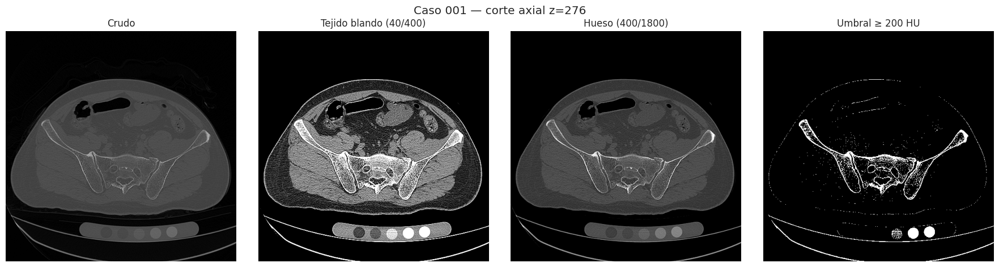

In [ ]:
def window_hu(vol, level=400, width=1800):
    lo, hi = level - width / 2, level + width / 2
    return ((np.clip(vol, lo, hi) - lo) / (hi - lo)).astype(np.float32)

def bone_mask(vol, thr=HU_BONE_THR):
    return vol >= thr

z = int(np.argmax(np.bincount(np.nonzero(lab0)[0])))   # corte con más etiqueta
wins = {"Crudo": None, "Tejido blando (40/400)": (40, 400), "Hueso (400/1800)": (400, 1800),
        f"Umbral ≥ {HU_BONE_THR} HU": "thr"}
fig, ax = plt.subplots(1, 4, figsize=(18, 4.8))
for a, (t, w) in zip(ax, wins.items()):
    if w is None:      im = img0[z]
    elif w == "thr":   im = bone_mask(img0[z])
    else:              im = window_hu(img0[z], *w)
    a.imshow(im, cmap="gray"); a.set_title(t); a.axis("off")
plt.suptitle(f"Caso {cases.case_id[0]} — corte axial z={z}"); plt.tight_layout(); plt.show()

## 4. EDA de volúmenes

Se recorre cada caso **una sola vez** y se extrae todo lo necesario (metadatos, intensidades muestreadas, fragmentos, estadísticas por corte). Los resultados se guardan en CSV para no recalcular.

In [ ]:
def fragment_table(case_id, region, inst, spacing):
    vox_mm3 = float(np.prod(spacing))
    rows = []
    for lbl in np.unique(inst[inst > 0]):
        m = inst == lbl
        r = int(np.bincount(region[m]).argmax())
        zz, yy, xx = np.nonzero(m)
        rows.append(dict(case_id=case_id, label=int(lbl), region=r, region_name=REGIONS[r],
                         n_vox=int(m.sum()), vol_mm3=m.sum() * vox_mm3,
                         z_min=zz.min(), z_max=zz.max(), n_slices=zz.max() - zz.min() + 1,
                         cz=zz.mean() * spacing[0], cy=yy.mean() * spacing[1], cx=xx.mean() * spacing[2],
                         n_components=int(ndi.label(m)[1])))
    df = pd.DataFrame(rows)
    if len(df):
        # Fragmento principal = el de mayor volumen dentro de su región (el dataset ordena por tamaño)
        df["is_main"] = df.groupby("region")["vol_mm3"].transform("max") == df["vol_mm3"]
        df["frag_rank"] = df.groupby("region")["vol_mm3"].rank(ascending=False, method="first").astype(int)
    return df

def slice_table(case_id, region, inst):
    rows = []
    for z in range(region.shape[0]):
        rz, iz = region[z], inst[z]
        if not rz.any():
            rows.append(dict(case_id=case_id, z=z, n_regions=0, n_frags=0)); continue
        d = dict(case_id=case_id, z=z, n_regions=len(np.unique(rz[rz > 0])),
                 n_frags=len(np.unique(iz[iz > 0])))
        for r in REGIONS:
            ys, xs = np.nonzero(rz == r)
            d[f"has_r{r}"] = len(ys) > 0
            d[f"frags_r{r}"] = len(np.unique(iz[rz == r])) if len(ys) else 0
            if len(ys):   # bbox 2D normalizada [0,1] -> insumo para diseñar la grilla de detección
                H, W = rz.shape
                d.update({f"bw_r{r}": (xs.max() - xs.min() + 1) / W, f"bh_r{r}": (ys.max() - ys.min() + 1) / H,
                          f"area_r{r}": len(ys) / (H * W)})
        rows.append(d)
    return rows

vol_rows, frag_dfs, slice_rows = [], [], []
hu_all, hu_bone = [], {r: [] for r in REGIONS}
rng = np.random.default_rng(SEED)

for _, c in tqdm(cases.iterrows(), total=len(cases)):
    img, meta, sitk_img = load_volume(c.image, np.int16)
    lab, lmeta, sitk_lab = load_volume(c.label, np.int16)
    assert img.shape == lab.shape, f"shape mismatch en {c.case_id}"
    scheme = detect_scheme(lab.max())
    region, inst = decode_labels(lab, scheme)
    sp = meta["spacing_zyx"]

    if CONVERT_TO_NIFTI:
        to_nifti(sitk_img, NIFTI_DIR / "images" / f"{c.case_id}.nii.gz")
        to_nifti(sitk_lab, NIFTI_DIR / "labels" / f"{c.case_id}.nii.gz")

    fr = region > 0
    vol_rows.append(dict(case_id=c.case_id, scheme=scheme,
                         nz=img.shape[0], ny=img.shape[1], nx=img.shape[2],
                         sp_z=sp[0], sp_y=sp[1], sp_x=sp[2],
                         fov_z_mm=img.shape[0] * sp[0], fov_xy_mm=img.shape[2] * sp[2],
                         hu_min=int(img.min()), hu_max=int(img.max()),
                         hu_p01=float(np.percentile(img[::4, ::4, ::4], 1)),
                         hu_p99=float(np.percentile(img[::4, ::4, ::4], 99)),
                         fg_frac=float(fr.mean()),
                         slices_with_label=int(fr.any(axis=(1, 2)).sum()),
                         has_femur=bool((lab > 150).any()) if scheme == "2026" else False,
                         spacing_match=np.allclose(sp, lmeta["spacing_zyx"])))

    frag_dfs.append(fragment_table(c.case_id, region, inst, sp))
    slice_rows += slice_table(c.case_id, region, inst)

    hu_all.append(rng.choice(img.ravel(), 20000, replace=False))
    for r in REGIONS:
        v = img[region == r]
        if v.size: hu_bone[r].append(rng.choice(v, min(20000, v.size), replace=False))

vols   = pd.DataFrame(vol_rows)
frags  = pd.concat(frag_dfs, ignore_index=True)
slices = pd.DataFrame(slice_rows)
vols.to_csv(OUT_DIR / "volumes.csv", index=False)
frags.to_csv(OUT_DIR / "fragments.csv", index=False)
slices.to_csv(OUT_DIR / "slices.csv", index=False)
print(vols.scheme.value_counts().to_dict(), "| fragmentos:", len(frags), "| cortes:", len(slices))

  0%|          | 0/100 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
vols   = pd.read_csv(OUT_DIR / "volumes.csv",   dtype={"case_id": str})
frags  = pd.read_csv(OUT_DIR / "fragments.csv", dtype={"case_id": str})
slices = pd.read_csv(OUT_DIR / "slices.csv",    dtype={"case_id": str})
print("EDA cargado desde Drive:", len(vols), "casos |", len(frags), "fragmentos |", len(slices), "cortes")

EDA cargado desde Drive: 100 casos | 575 fragmentos | 32106 cortes


### 4.1 Calidad de datos

In [ ]:
checks = pd.Series({
    "Casos": len(vols),
    "Spacing imagen ≠ etiqueta": int((~vols.spacing_match).sum()),
    "Casos con fémur (ignorado)": int(vols.has_femur.sum()),
    "Fragmentos con >1 componente conexa": int((frags.n_components > 1).sum()),
    "Fragmentos < 500 mm³": int((frags.vol_mm3 < 500).sum()),
    "Casos sin alguna de las 3 regiones": int((frags.groupby("case_id").region.nunique() < 3).sum()),
})
display(checks.to_frame("valor"))
vols.describe().T.round(3)

,valor
Casos,100
Spacing imagen ≠ etiqueta,0
Casos con fémur (ignorado),0
Fragmentos con >1 componente conexa,136
Fragmentos < 500 mm³,2
Casos sin alguna de las 3 regiones,0


,count,mean,std,min,25%,50%,75%,max
scheme,100.0,2024.000,0.000,2024.000,2024.000,2024.000,2024.000,2024.000
nz,100.0,321.060,43.495,193.000,285.750,326.000,350.000,414.000
ny,100.0,427.670,116.890,154.000,299.500,512.000,512.000,512.000
nx,100.0,490.010,43.316,322.000,508.000,512.000,512.000,512.000
sp_z,100.0,0.891,0.109,0.625,0.800,0.801,1.000,1.250
sp_y,100.0,0.819,0.079,0.658,0.781,0.798,0.858,1.220
sp_x,100.0,0.819,0.079,0.658,0.781,0.798,0.858,1.220
fov_z_mm,100.0,282.232,24.436,224.000,266.850,279.998,298.100,353.000
fov_xy_mm,100.0,399.820,42.356,307.051,376.523,400.000,425.854,499.712
hu_min,100.0,-1801.860,3203.292,-32295.000,-2048.000,-1023.000,-1023.000,-1023.000


### 4.2 Geometría y espaciado físico

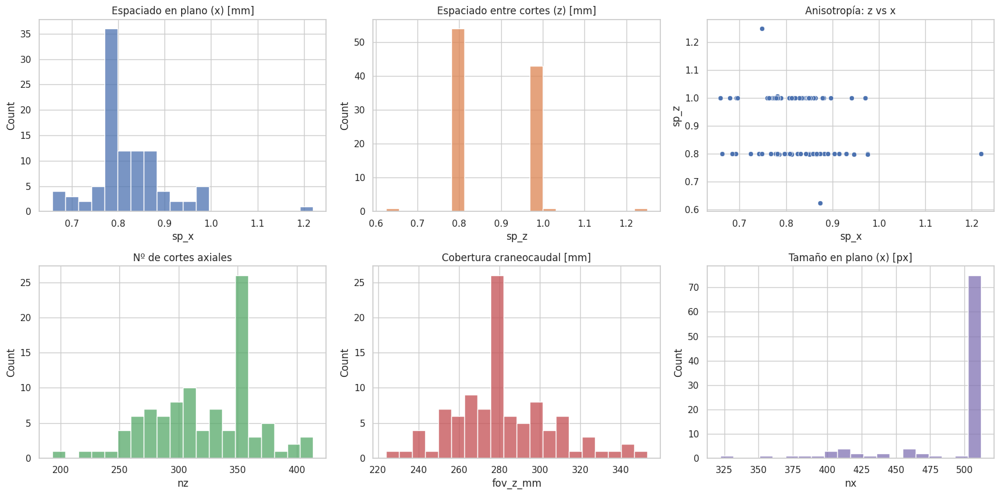

Factor de escala al redimensionar a 256px: mm/px efectivo = {'min': 1.2, 'mean': 1.56, 'max': 1.95}


In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(17, 8.5))
sns.histplot(vols.sp_x, ax=ax[0, 0], bins=20); ax[0, 0].set_title("Espaciado en plano (x) [mm]")
sns.histplot(vols.sp_z, ax=ax[0, 1], bins=20, color="C1"); ax[0, 1].set_title("Espaciado entre cortes (z) [mm]")
sns.scatterplot(data=vols, x="sp_x", y="sp_z", ax=ax[0, 2]); ax[0, 2].set_title("Anisotropía: z vs x")
sns.histplot(vols.nz, ax=ax[1, 0], bins=20, color="C2"); ax[1, 0].set_title("Nº de cortes axiales")
sns.histplot(vols.fov_z_mm, ax=ax[1, 1], bins=20, color="C3"); ax[1, 1].set_title("Cobertura craneocaudal [mm]")
sns.histplot(vols.nx, ax=ax[1, 2], bins=20, color="C4"); ax[1, 2].set_title("Tamaño en plano (x) [px]")
plt.tight_layout(); plt.show()
print(f"Factor de escala al redimensionar a {TARGET_SIZE}px: mm/px efectivo = "
      f"{(vols.fov_xy_mm / TARGET_SIZE).describe()[['min','mean','max']].round(2).to_dict()}")

## 5. EDA de fragmentos por caso

In [ ]:
per_case = (frags.groupby(["case_id", "region_name"]).size().unstack(fill_value=0)
            .reindex(columns=list(REGIONS.values()), fill_value=0))
per_case["Total"] = per_case.sum(axis=1)
per_case["Regiones fracturadas"] = (per_case[list(REGIONS.values())] > 1).sum(axis=1)
per_case.to_csv(OUT_DIR / "fragments_per_case.csv")

summary = pd.DataFrame({
    "% casos fracturados": (per_case[list(REGIONS.values())] > 1).mean() * 100,
    "Fragmentos medios": per_case[list(REGIONS.values())].mean(),
    "Máx. fragmentos": per_case[list(REGIONS.values())].max(),
}).round(2)
display(summary)
per_case.describe().round(2)

,% casos fracturados,Fragmentos medios,Máx. fragmentos
region_name,,,
Sacro,45.0,1.53,4
Coxal izq.,66.0,2.15,6
Coxal der.,64.0,2.07,4


region_name,Sacro,Coxal izq.,Coxal der.,Total,Regiones fracturadas
count,100.00,100.00,100.00,100.00,100.00
mean,1.53,2.15,2.07,5.75,1.75
std,0.66,1.07,0.99,1.22,0.73
min,1.00,1.00,1.00,3.00,0.00
25%,1.00,1.00,1.00,5.00,1.00
50%,1.00,2.00,2.00,6.00,2.00
75%,2.00,3.00,3.00,7.00,2.00
max,4.00,6.00,4.00,9.00,3.00


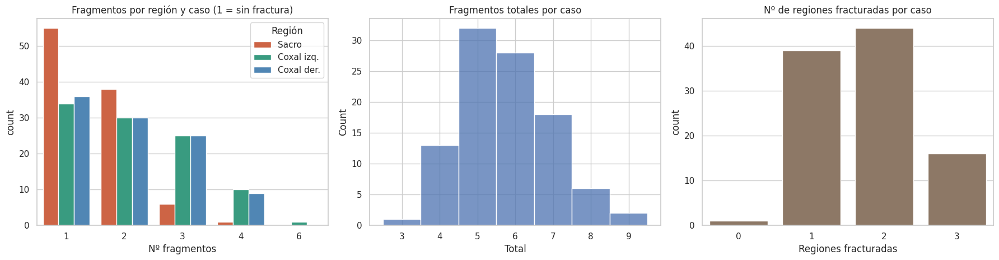

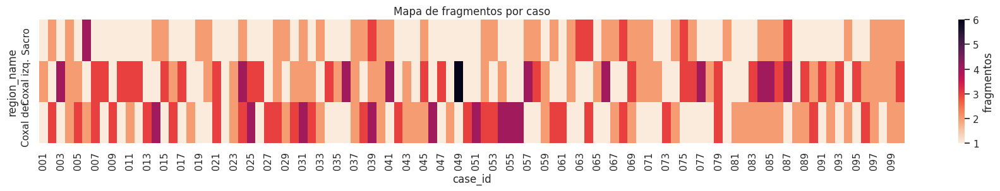

In [ ]:
pal = {REGIONS[r]: REGION_COLORS[r] for r in REGIONS}
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
long = per_case[list(REGIONS.values())].melt(var_name="Región", value_name="n")
sns.countplot(data=long, x="n", hue="Región", palette=pal, ax=ax[0])
ax[0].set_title("Fragmentos por región y caso (1 = sin fractura)"); ax[0].set_xlabel("Nº fragmentos")
sns.histplot(per_case.Total, discrete=True, ax=ax[1]); ax[1].set_title("Fragmentos totales por caso")
sns.countplot(x=per_case["Regiones fracturadas"], ax=ax[2], color="C5")
ax[2].set_title("Nº de regiones fracturadas por caso")
plt.tight_layout(); plt.show()

plt.figure(figsize=(18, 3.2))
sns.heatmap(per_case[list(REGIONS.values())].T, cmap="rocket_r", cbar_kws={"label": "fragmentos"},
            xticklabels=max(1, len(per_case) // 40))
plt.title("Mapa de fragmentos por caso"); plt.xlabel("case_id"); plt.tight_layout(); plt.show()

### 5.1 Tamaño de fragmentos: principal vs conminutos

Se espera un fuerte desbalance: el fragmento principal ocupa casi todo el volumen del hueso y los conminutos son órdenes de magnitud menores. Esto condiciona la pérdida (Dice/focal) y el riesgo de que los fragmentos pequeños desaparezcan al redimensionar a 256 px.

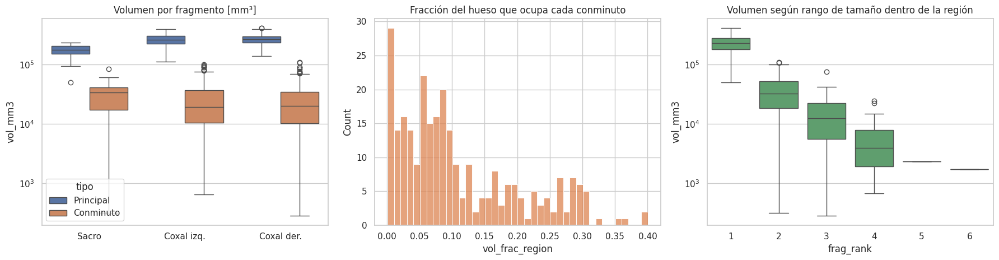

Conminutos: 275 | mediana 22183 mm³ | diámetro equivalente mediano 34.9 mm ≈ 22.3 px a 256px
Conminutos con diámetro eq. < 3 px tras resize: 0.0%


In [ ]:
frags["tipo"] = np.where(frags.is_main, "Principal", "Conminuto")
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
sns.boxplot(data=frags, x="region_name", y="vol_mm3", hue="tipo", ax=ax[0], order=list(REGIONS.values()))
ax[0].set_yscale("log"); ax[0].set_title("Volumen por fragmento [mm³]"); ax[0].set_xlabel("")

tot = frags.groupby(["case_id", "region"]).vol_mm3.transform("sum")
frags["vol_frac_region"] = frags.vol_mm3 / tot
sns.histplot(frags.loc[~frags.is_main, "vol_frac_region"], bins=40, ax=ax[1], color="C1")
ax[1].set_title("Fracción del hueso que ocupa cada conminuto")

sns.boxplot(data=frags, x="frag_rank", y="vol_mm3", ax=ax[2], color="C2")
ax[2].set_yscale("log"); ax[2].set_title("Volumen según rango de tamaño dentro de la región")
plt.tight_layout(); plt.show()

conm = frags[~frags.is_main]
mm_px = (vols.fov_xy_mm / TARGET_SIZE).mean()
eq_diam = 2 * (3 * conm.vol_mm3 / (4 * np.pi)) ** (1 / 3)
print(f"Conminutos: {len(conm)} | mediana {conm.vol_mm3.median():.0f} mm³ | "
      f"diámetro equivalente mediano {eq_diam.median():.1f} mm ≈ {eq_diam.median()/mm_px:.1f} px a {TARGET_SIZE}px")
print(f"Conminutos con diámetro eq. < 3 px tras resize: {(eq_diam / mm_px < 3).mean()*100:.1f}%")

### 5.2 Balance de clases a nivel de vóxel

In [ ]:
vox = frags.groupby("region_name").n_vox.sum().reindex(REGIONS.values())
bg = (vols.nz * vols.ny * vols.nx).sum() - vox.sum()
share = pd.concat([pd.Series({"Fondo": bg}), vox]); share = share / share.sum() * 100
display(share.round(3).to_frame("% vóxeles"))
w = (1 / share) / (1 / share).sum()
print("Pesos inversos a la frecuencia (referencia para calibrar λ / class weights):", w.round(4).to_dict())

,% vóxeles
Fondo,98.027
Sacro,0.481
Coxal izq.,0.743
Coxal der.,0.749


Pesos inversos a la frecuencia (referencia para calibrar λ / class weights): {'Fondo': 0.0021, 'Sacro': 0.4358, 'Coxal izq.': 0.2822, 'Coxal der.': 0.2799}


## 6. EDA a nivel de corte 2D

El modelo trabaja corte a corte, por lo que el desbalance relevante es el de **cortes**: cuántos cortes no contienen hueso, cuántas regiones aparecen por corte y qué tamaño tienen las cajas a detectar.

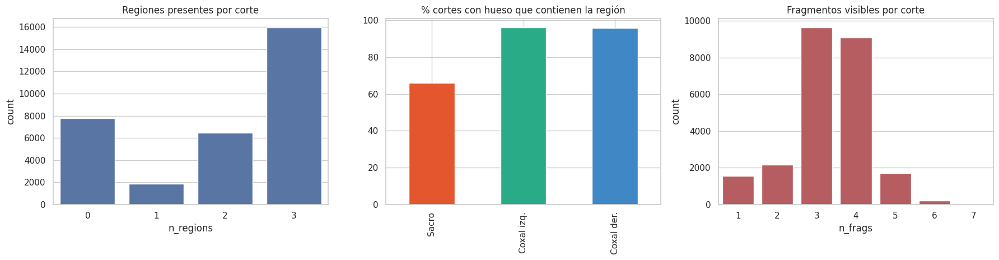

Cortes totales: 32106 | con hueso anotado: 24316 (75.7%)


In [ ]:
lab_sl = slices[slices.n_regions > 0]
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
sns.countplot(x=slices.n_regions, ax=ax[0], color="C0"); ax[0].set_title("Regiones presentes por corte")
pres = pd.Series({REGIONS[r]: lab_sl[f"has_r{r}"].mean() * 100 for r in REGIONS})
pres.plot.bar(ax=ax[1], color=[REGION_COLORS[r] for r in REGIONS]); ax[1].set_title("% cortes con hueso que contienen la región")
sns.countplot(x=lab_sl.n_frags, ax=ax[2], color="C3"); ax[2].set_title("Fragmentos visibles por corte")
plt.tight_layout(); plt.show()
print(f"Cortes totales: {len(slices)} | con hueso anotado: {len(lab_sl)} ({len(lab_sl)/len(slices)*100:.1f}%)")

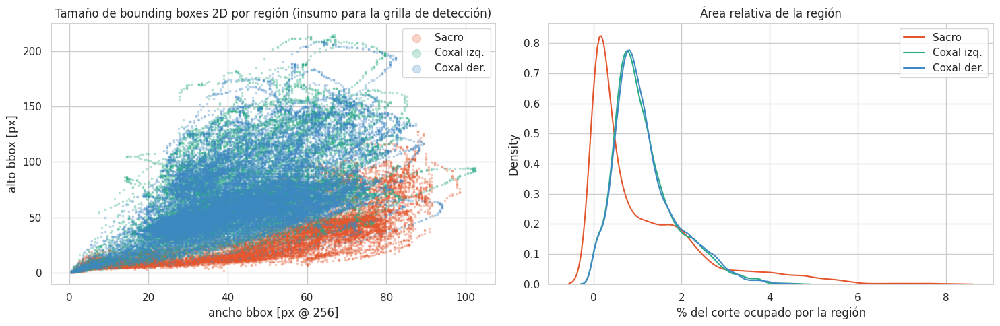

w                                                  h        \
              count  mean   std  min    5%   50%   95%    max    count  mean   
region                                                                         
Coxal der.  23275.0  43.6  16.5  0.5  19.5  42.5  71.5   94.0  23275.0  69.5   
Coxal izq.  23411.0  42.9  16.3  0.5  19.5  41.5  71.0  102.4  23411.0  69.8   
Sacro       16052.0  46.6  25.7  0.5   5.5  51.5  82.0   98.5  16052.0  29.7   

                                                 
             std  min    5%   50%    95%    max  
region                                           
Coxal der.  34.5  0.5  22.6  62.0  137.8  208.4  
Coxal izq.  35.0  0.5  23.0  63.5  139.9  214.1  
Sacro       23.5  0.5   5.0  23.0   81.7  127.3

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for r in REGIONS:
    s = lab_sl.dropna(subset=[f"bw_r{r}"])
    ax[0].scatter(s[f"bw_r{r}"] * TARGET_SIZE, s[f"bh_r{r}"] * TARGET_SIZE, s=3, alpha=.25,
                  c=REGION_COLORS[r], label=REGIONS[r])
    sns.kdeplot(s[f"area_r{r}"] * 100, ax=ax[1], color=REGION_COLORS[r], label=REGIONS[r])
ax[0].set_xlabel(f"ancho bbox [px @ {TARGET_SIZE}]"); ax[0].set_ylabel("alto bbox [px]"); ax[0].legend(markerscale=5)
ax[0].set_title("Tamaño de bounding boxes 2D por región (insumo para la grilla de detección)")
ax[1].set_xlabel("% del corte ocupado por la región"); ax[1].legend(); ax[1].set_title("Área relativa de la región")
plt.tight_layout(); plt.show()

bb = pd.concat([pd.DataFrame({"w": lab_sl[f"bw_r{r}"], "h": lab_sl[f"bh_r{r}"], "region": REGIONS[r]}).dropna()
                for r in REGIONS])
(bb[["w", "h"]] * TARGET_SIZE).groupby(bb.region).describe(percentiles=[.05, .5, .95]).round(1)

### 6.1 Galería: cortes con overlay de GT y bounding boxes por región

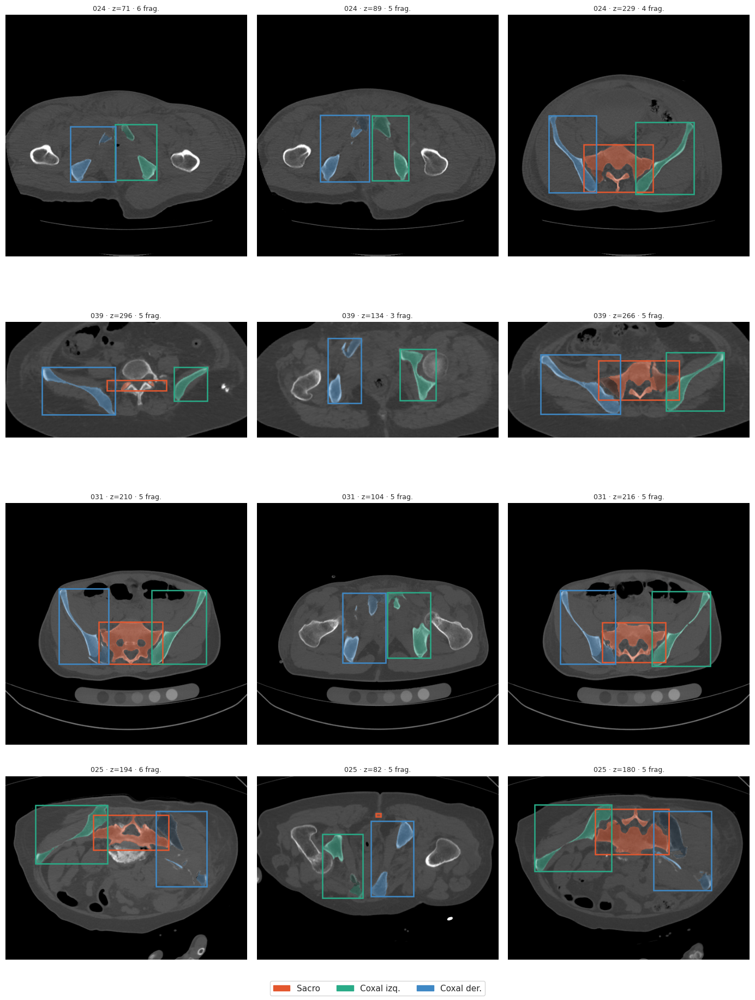

In [ ]:
def overlay_slice(ax, img2d, reg2d, inst2d, title=""):
    ax.imshow(window_hu(img2d, **WINDOW), cmap="gray")
    rgba = np.zeros((*reg2d.shape, 4))
    for r, col in REGION_COLORS.items():
        m = reg2d == r
        if not m.any(): continue
        rgb = np.array([int(col[i:i + 2], 16) / 255 for i in (1, 3, 5)])
        # tonos distintos por fragmento dentro de la región
        for k, lbl in enumerate(np.unique(inst2d[m])):
            rgba[inst2d == lbl] = [*(rgb * (1 - 0.35 * k)).clip(0, 1), 0.45]
        ys, xs = np.nonzero(m)
        ax.add_patch(mpatches.Rectangle((xs.min(), ys.min()), np.ptp(xs), np.ptp(ys), fill=False, ec=col, lw=1.8))
    ax.imshow(rgba); ax.set_title(title, fontsize=9); ax.axis("off")

# casos más conminutos
top = per_case.sort_values("Total", ascending=False).head(4).index
fig, axes = plt.subplots(len(top), 3, figsize=(14, 4.6 * len(top)))
axes = np.atleast_2d(axes)
for row, cid in zip(axes, top):
    c = cases.set_index("case_id").loc[cid]
    img, _, _ = load_volume(c.image, np.int16); lab, _, _ = load_volume(c.label, np.int16)
    reg, ins = decode_labels(lab, detect_scheme(lab.max()))
    s = slices[(slices.case_id == cid)].sort_values("n_frags", ascending=False)
    zs = s.z.iloc[:1].tolist() + s[s.n_frags > 0].z.quantile([.25, .75]).astype(int).tolist()
    for a, z in zip(row, zs):
        overlay_slice(a, img[z], reg[z], ins[z], f"{cid} · z={z} · {int(s.set_index('z').loc[z, 'n_frags'])} frag.")
handles = [mpatches.Patch(color=REGION_COLORS[r], label=REGIONS[r]) for r in REGIONS]
fig.legend(handles=handles, loc="lower center", ncol=3); plt.tight_layout(); plt.show()

## 7. Distancia de separación en el ground truth

Para cada fragmento conminuto: distancia mínima borde a borde (mm) al fragmento principal del mismo hueso, con `distance_transform_edt(~principal, sampling=spacing)`. Se recorta al *bounding box* de la región para ahorrar memoria. Esta es la **referencia GT** contra la que luego se comparará la distancia medida sobre las máscaras predichas.

*Nota:* la EDT mide distancia centro-a-centro de vóxel; fragmentos en contacto dan ≈ 1 espaciado (no 0). Se documenta como limitación.

  0%|          | 0/100 [00:00<?, ?it/s]

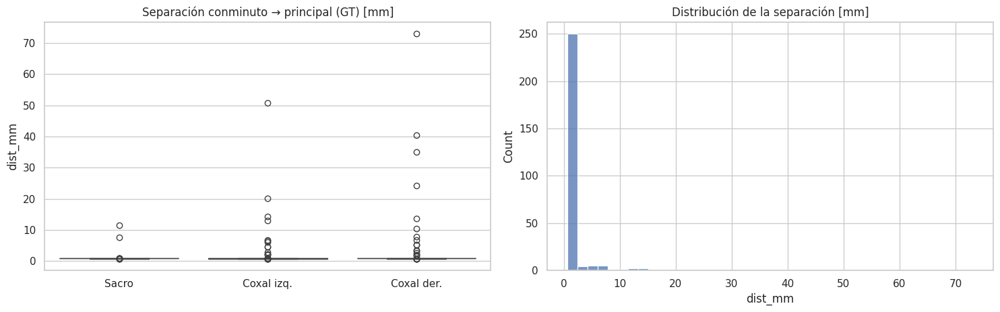

             count  mean   std   min   25%   50%   75%    max
region_name                                                  
Coxal der.   107.0  2.88  8.93  0.62  0.78  0.80  0.83  73.12
Coxal izq.   115.0  1.88  5.30  0.66  0.78  0.78  0.83  50.82
Sacro         53.0  1.13  1.72  0.66  0.78  0.80  0.81  11.52
Conminutos prácticamente en contacto con el principal: 90.9% (riesgo de fusión por errores de segmentación → model card)


In [ ]:
def separation_distances(inst, region, spacing, margin=5):
    out = []
    for r in REGIONS:
        rm = region == r
        if not rm.any(): continue
        labels, counts = np.unique(inst[rm], return_counts=True)
        if len(labels) < 2: continue
        main = labels[np.argmax(counts)]
        sl = tuple(slice(max(s.start - margin, 0), s.stop + margin) for s in ndi.find_objects(rm.astype(np.uint8))[0])
        sub = inst[sl]
        dt = ndi.distance_transform_edt(sub != main, sampling=spacing)
        for lbl in labels:
            if lbl == main: continue
            out.append(dict(region=r, label=int(lbl), main_label=int(main),
                            dist_mm=float(dt[sub == lbl].min())))
    return out

dist_rows = []
for _, c in tqdm(cases.iterrows(), total=len(cases)):
    lab, meta, _ = load_volume(c.label, np.int16)
    reg, ins = decode_labels(lab, detect_scheme(lab.max()))
    for d in separation_distances(ins, reg, meta["spacing_zyx"]):
        dist_rows.append({"case_id": c.case_id, **d})
dist = pd.DataFrame(dist_rows)
dist["region_name"] = dist.region.map(REGIONS)
dist.to_csv(OUT_DIR / "separation_gt.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
sns.boxplot(data=dist, x="region_name", y="dist_mm", palette=pal, ax=ax[0], order=list(REGIONS.values()))
ax[0].set_title("Separación conminuto → principal (GT) [mm]"); ax[0].set_xlabel("")
sns.histplot(dist.dist_mm, bins=40, ax=ax[1]); ax[1].set_title("Distribución de la separación [mm]")
plt.tight_layout(); plt.show()
touch = (dist.dist_mm <= vols.sp_x.max() * 1.8).mean() * 100
print(dist.groupby("region_name").dist_mm.describe().round(2))
print(f"Conminutos prácticamente en contacto con el principal: {touch:.1f}% "
      "(riesgo de fusión por errores de segmentación → model card)")

In [ ]:
dist = pd.read_csv(OUT_DIR / "separation_gt.csv", dtype={"case_id": str})

## 8. Splits fijos (a nivel de paciente)

El split se hace **por caso** (nunca por corte) para evitar fuga de información entre cortes vecinos del mismo paciente. Se estratifica por un proxy del patrón de fractura: número de regiones fracturadas × severidad (fragmentos totales). Semilla fija y archivo versionable.

In [ ]:
strat = per_case["Regiones fracturadas"].astype(str) + "_" + pd.cut(
    per_case.Total, bins=[0, 3, 5, 100], labels=["leve", "media", "severa"]).astype(str)
# colapsar estratos con menos de 3 casos
strat = strat.where(strat.map(strat.value_counts()) >= 3, "otros")

ids = per_case.index.to_numpy()
def safe_split(x, y, test_size):
    try:    return train_test_split(x, test_size=test_size, random_state=SEED, stratify=y)
    except ValueError:
        return train_test_split(x, test_size=test_size, random_state=SEED)

train_ids, tmp_ids = safe_split(ids, strat.loc[ids], 0.30)
val_ids, test_ids  = safe_split(tmp_ids, strat.loc[tmp_ids], 0.50)
splits = {"seed": SEED, "train": sorted(map(str, train_ids)), "val": sorted(map(str, val_ids)),
          "test": sorted(map(str, test_ids))}
json.dump(splits, open(OUT_DIR / "splits.json", "w"), indent=2)

split_of = {i: k for k in ("train", "val", "test") for i in splits[k]}
per_case["split"] = per_case.index.map(lambda i: split_of[str(i)])
chk = per_case.groupby("split").agg(casos=("Total", "size"), frag_medios=("Total", "mean"),
                                   pct_multirregion=("Regiones fracturadas", lambda s: (s > 1).mean() * 100))
chk["cortes_con_hueso"] = lab_sl.assign(split=lab_sl.case_id.map(lambda i: split_of[str(i)])).groupby("split").size()
display(chk.round(2))

,casos,frag_medios,pct_multirregion,cortes_con_hueso
split,,,,
test,15,5.60,53.33,3671
train,70,5.81,61.43,16941
val,15,5.60,60.00,3704


## 9. Visualizador 1 — Volumen crudo: MIP con umbral HU (solo hueso)

Preprocesamiento clásico, sin modelo:
1. Umbral `HU ≥ HU_BONE_THR` sobre el volumen sin procesar.
2. Limpieza: se descartan las componentes conexas 3D de menos de 2000 mm³ (ruido, calcificaciones, bordes de la camilla).
3. **MIP** en las tres vistas y **MIP rotacional 360°**: el volumen se remuestrea a vóxel isotrópico de 2 mm (usando el espaciado del header, para que la rotación no deforme la pelvis), se rota alrededor del eje craneocaudal y en cada ángulo se proyecta el máximo. El resultado es una reconstrucción 3D por proyección con *slider* y botón de reproducción en Plotly.

Todas las escalas en mm usando el espaciado del header.

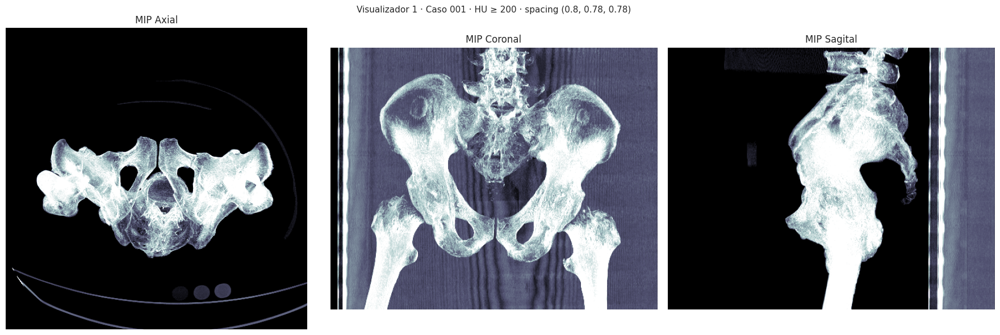

In [ ]:
def remove_table(mask, min_mm3=2000, spacing=(1, 1, 1)):
    # Conserva las componentes conexas 3D de al menos min_mm3 (descarta ruido y calcificaciones aisladas)
    lab, n = ndi.label(mask)
    if n == 0: return mask
    sizes = ndi.sum(mask, lab, range(1, n + 1)) * np.prod(spacing)
    keep = np.isin(lab, np.nonzero(sizes >= min_mm3)[0] + 1)
    return keep

def bone_only(vol, spacing, thr=HU_BONE_THR, clean=True):
    m = bone_mask(vol, thr)
    if clean: m = remove_table(m, spacing=spacing)
    return np.where(m, vol, vol.min()).astype(np.float32)

def mip_views(case_id, thr=HU_BONE_THR):
    c = cases.set_index("case_id").loc[case_id]
    vol, meta, _ = load_volume(c.image, np.int16); sp = meta["spacing_zyx"]
    b = bone_only(vol, sp, thr)
    views = {"Axial": (b.max(0), sp[1] / sp[2]), "Coronal": (b.max(1)[::-1], sp[0] / sp[2]),
             "Sagital": (b.max(2)[::-1], sp[0] / sp[1])}
    fig, ax = plt.subplots(1, 3, figsize=(18, 6))
    for a, (t, (im, asp)) in zip(ax, views.items()):
        a.imshow(np.clip(im, thr, 1500), cmap="bone", aspect=asp); a.set_title(f"MIP {t}"); a.axis("off")
    plt.suptitle(f"Visualizador 1 · Caso {case_id} · HU ≥ {thr} · spacing {tuple(round(s,2) for s in sp)}", fontsize=11)
    plt.tight_layout(); plt.show()
    return b, sp

b, sp = mip_views(cases.case_id[0])

def mip_rotacional(case_id, thr=HU_BONE_THR, iso_mm=2.0, step=10, hu_max=1500):
    c = cases.set_index("case_id").loc[case_id]
    vol, meta, _ = load_volume(c.image, np.int16); sp = np.array(meta["spacing_zyx"])
    b = bone_only(vol, tuple(sp), thr)
    b = ndi.zoom(b, sp / iso_mm, order=1)                                   # vóxel isotrópico de iso_mm
    b = ((np.clip(b, thr, hu_max) - thr) / (hu_max - thr) * 255).astype(np.uint8)
    angs = list(range(0, 360, step)); frames = []
    for a in angs:
        r = ndi.rotate(b, a, axes=(1, 2), reshape=False, order=1, mode="constant", cval=0)   # giro sobre el eje z
        frames.append(r.max(axis=1)[::-1])                                   # proyección anteroposterior
    nz_, nx_ = frames[0].shape
    hm = lambda f: go.Heatmap(z=f, colorscale="gray", showscale=False, zmin=0, zmax=255,
                              x=np.arange(nx_) * iso_mm, y=np.arange(nz_) * iso_mm)
    fig = go.Figure(data=[hm(frames[0])], frames=[go.Frame(data=[hm(f)], name=str(a)) for a, f in zip(angs, frames)])
    fig.update_layout(
        title=f"Visualizador 1 · Caso {case_id} · MIP rotacional (HU ≥ {thr}, vóxel {iso_mm} mm)",
        xaxis=dict(title="mm", scaleanchor="y"), yaxis=dict(title="mm"), height=620, plot_bgcolor="black",
        updatemenus=[dict(type="buttons", x=0, y=-0.08, xanchor="left", buttons=[
            dict(label="▶ Girar", method="animate", args=[None, dict(frame=dict(duration=80, redraw=True), fromcurrent=True)]),
            dict(label="⏸", method="animate", args=[[None], dict(mode="immediate", frame=dict(duration=0))])])],
        sliders=[dict(currentvalue=dict(prefix="ángulo: ", suffix="°"), pad=dict(t=40),
                      steps=[dict(label=str(a), method="animate",
                                  args=[[str(a)], dict(mode="immediate", frame=dict(duration=0, redraw=True))]) for a in angs])])
    return fig

fig_mip = mip_rotacional(cases.case_id[0])
fig_mip.write_html(OUT_DIR / f"visualizador1_{cases.case_id[0]}.html", include_plotlyjs="cdn")
fig_mip.show()

---
# PENGWIN — Semana 9: Backbone + CBAM + cabeza de detección en grilla 9×9

**Requisito del avance:** backbone, CBAM y cabeza de detección implementados; overfit intencional sobre un batch pequeño como prueba de correctitud; primeras predicciones de bounding boxes.

**Diseño de la salida (pista del profesor):** la red reescribe cada corte de 256×256 como un tensor **9×9 con ≤ 10 canales**. Cada celda predice:

| Canal | Contenido | Activación |
|---|---|---|
| 0 | objectness (¿hay un centro de región en esta celda?) | sigmoide |
| 1–2 | centro (x, y) relativo a la celda | sigmoide |
| 3–4 | ancho y alto relativos a la imagen | sigmoide |
| 5–7 | clase: Sacro / Coxal izq. / Coxal der. | softmax |

→ **8 canales × 9 × 9** (dentro del límite de 10). Sin anchors: cada objeto se asigna a la celda que contiene su centro. NMS e IoU implementados por el equipo (sin `torchvision.ops`).

```
corte 1×256×256 → FundidoraPC (Taller 3, 256→16) → CBAM → conv s2 p2 (16→9) → cabeza det. → 8×9×9
                                          └→ cabeza de clasificación (presencia de región)
                                          └→ [semana 10] cabeza de segmentación de instancia
```

In [ ]:
import time, math
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"          # precisión mixta (torch.cuda.amp) solo en GPU
torch.manual_seed(SEED)

S          = 9                    # grilla 9×9
NC         = len(REGIONS)         # 3 clases
NOUT       = 5 + NC               # obj + (x, y, w, h) + 3 clases = 8 canales (≤ 10)
MIN_BOX_PX = 4                    # descarta cajas diminutas de cortes de borde (EDA: w mín = 0.5 px)
NEG_FRAC   = 0.10                 # fracción de cortes SIN hueso que se conservan como negativos
BATCH      = 16
N_EPOCHS   = 15
OVERFIT_ITERS = 300
print(DEVICE, f"| salida de la cabeza: {NOUT}×{S}×{S} | celda = {TARGET_SIZE/S:.1f} px")

cuda | salida de la cabeza: 8×9×9 | celda = 28.4 px


## 10. Caché de cortes 2D (256×256) y cajas por región

Por caso: ventana ósea → *padding* a cuadrado (conserva la relación de aspecto) → resize a 256. Las cajas GT se calculan sobre la máscara de región a resolución original y se escalan con la misma transformación. Se guarda `mm_px` por corte para convertir a milímetros más adelante.

In [ ]:
def prep_case(case_id, size=TARGET_SIZE, neg_frac=NEG_FRAC, rng=np.random.default_rng(SEED)):
    c = cases.set_index("case_id").loc[case_id]
    img, meta, _ = load_volume(c.image, np.int16)
    lab, _, _    = load_volume(c.label, np.int16)
    reg, _ = decode_labels(lab, detect_scheme(lab.max()))
    nz, ny, nx = img.shape
    side = max(ny, nx); py, px = (side - ny) // 2, (side - nx) // 2; scale = size / side

    has  = reg.reshape(nz, -1).any(1)
    keep = np.nonzero(has | (rng.random(nz) < neg_frac))[0]

    x = window_hu(img[keep], **WINDOW)
    x = np.pad(x, ((0, 0), (py, side - ny - py), (px, side - nx - px)))
    x = F.interpolate(torch.from_numpy(x)[:, None], size=(size, size), mode="bilinear", align_corners=False)[:, 0]
    x = (x.clamp(0, 1) * 255).round().to(torch.uint8).numpy()

    boxes = []
    for z in keep:
        bz = []
        for r in REGIONS:
            ys, xs = np.nonzero(reg[z] == r)
            if len(ys) == 0: continue
            x0, y0 = (xs.min() + px) * scale, (ys.min() + py) * scale
            x1, y1 = (xs.max() + 1 + px) * scale, (ys.max() + 1 + py) * scale
            if min(x1 - x0, y1 - y0) < MIN_BOX_PX: continue
            bz.append([x0, y0, x1, y1, r - 1])            # clase 0..2
        boxes.append(np.array(bz, np.float32).reshape(-1, 5))
    mm_px = meta["spacing_zyx"][2] / scale
    return x, boxes, keep, mm_px

def build_split(ids):
    X, B, M = [], [], []
    for cid in tqdm(ids, desc="cache"):
        x, b, zs, mmpx = prep_case(cid)
        X.append(x); B += b; M += [(cid, int(z), mmpx) for z in zs]
    return np.concatenate(X), B, pd.DataFrame(M, columns=["case_id", "z", "mm_px"])

CACHE = {k: build_split(splits[k]) for k in ("train", "val", "test")}
for k, (X, B, M) in CACHE.items():
    print(f"{k:5s}: {len(X):5d} cortes | {sum(len(b) for b in B):5d} cajas | "
          f"{np.mean([len(b) == 0 for b in B])*100:4.1f}% negativos | {X.nbytes/1e6:.0f} MB")

cache:   0%|          | 0/70 [00:00<?, ?it/s]

cache:   0%|          | 0/15 [00:00<?, ?it/s]

cache:   0%|          | 0/15 [00:00<?, ?it/s]

train: 17455 cortes | 43325 cajas |  3.5% negativos | 1144 MB
val  :  3804 cortes |  9297 cajas |  3.1% negativos | 249 MB
test :  3780 cortes |  9360 cajas |  3.4% negativos | 248 MB


## 11. Codificación del target en la grilla y justificación del 9×9

Cada caja se asigna a la celda que contiene su centro. Si dos regiones caen en la misma celda (**colisión**), solo una puede predecirse: ese es el criterio para elegir S. Se compara la tasa de colisión para varios tamaños de grilla sobre las cajas reales de entrenamiento.

    celda_px  colision_pct
S                         
4       64.0         9.002
5       51.2         1.648
7       36.6         0.044
8       32.0         0.007
9       28.4         0.016
12      21.3         0.000
16      16.0         0.000


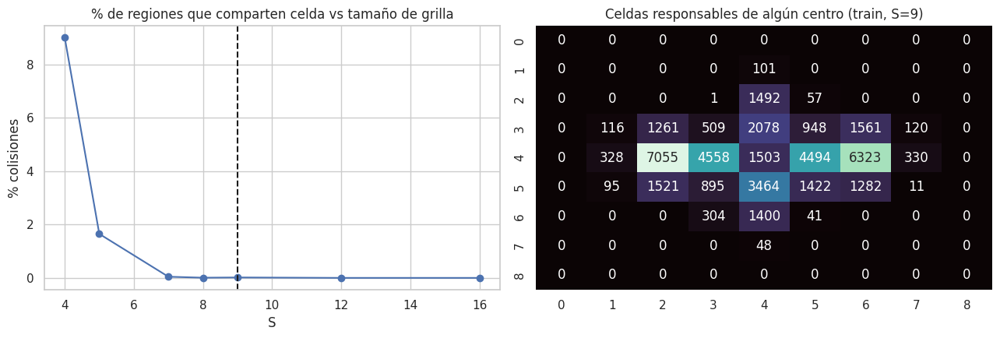

In [ ]:
def encode_target(boxes, size=TARGET_SIZE, S=S):
    # -> tgt (5,S,S): [obj, x_off, y_off, w_rel, h_rel] ; cls_map (S,S) con -1 en celdas vacías
    tgt = torch.zeros(5, S, S); cls_map = torch.full((S, S), -1, dtype=torch.long)
    cell, coll = size / S, 0
    order = np.argsort(-(boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])) if len(boxes) else []
    for i in order:                                    # la caja más grande gana la celda en caso de colisión
        x0, y0, x1, y1, c = boxes[i]
        cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
        gi, gj = min(int(cx // cell), S - 1), min(int(cy // cell), S - 1)
        if tgt[0, gj, gi] == 1: coll += 1; continue
        tgt[:, gj, gi] = torch.tensor([1., cx / cell - gi, cy / cell - gj, (x1 - x0) / size, (y1 - y0) / size])
        cls_map[gj, gi] = int(c)
    return tgt, cls_map, coll

train_boxes = CACHE["train"][1]
n_obj = sum(len(b) for b in train_boxes)
grid_cmp = pd.DataFrame([dict(S=s, celda_px=round(TARGET_SIZE / s, 1),
                              colision_pct=round(sum(encode_target(b, S=s)[2] for b in train_boxes) / n_obj * 100, 3))
                         for s in (4, 5, 7, 8, 9, 12, 16)]).set_index("S")
print(grid_cmp)

occ = torch.zeros(S, S)
for b in train_boxes: occ += encode_target(b)[0][0]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
grid_cmp.colision_pct.plot(marker="o", ax=ax[0]); ax[0].axvline(S, ls="--", c="k")
ax[0].set_title("% de regiones que comparten celda vs tamaño de grilla"); ax[0].set_ylabel("% colisiones")
sns.heatmap(occ.numpy(), annot=True, fmt=".0f", cmap="mako", ax=ax[1], cbar=False)
ax[1].set_title(f"Celdas responsables de algún centro (train, S={S})")
plt.tight_layout(); plt.show()
POS_PER_IMG = n_obj / len(train_boxes)

In [ ]:
class SliceDS(Dataset):
    def __init__(self, X, B): self.X, self.B = X, B
    def __len__(self): return len(self.X)
    def __getitem__(self, i):
        x = torch.from_numpy(self.X[i]).float().div_(255)[None]
        b = self.B[i]
        tgt, cls_map, _ = encode_target(b)
        pres = torch.zeros(NC); pres[b[:, 4].astype(int)] = 1      # presencia de región (cabeza de clasificación)
        return x, tgt, cls_map, pres, b

def collate(batch):
    x, t, c, p, g = zip(*batch)
    return torch.stack(x), torch.stack(t), torch.stack(c), torch.stack(p), list(g)

ds = {k: SliceDS(*CACHE[k][:2]) for k in CACHE}
g = torch.Generator().manual_seed(SEED)
loaders = {k: DataLoader(ds[k], batch_size=BATCH, shuffle=(k == "train"), collate_fn=collate, generator=g,
                         num_workers=2, pin_memory=DEVICE.type == "cuda") for k in ds}

## 12. Arquitectura: FundidoraPC + CBAM + tres cabezas

- **`FundidoraPC`** (Taller 3, sin cambios): 4 bloques conv+pool → `256×16×16` a 256 px. Para CT (1 canal) los pesos de la primera conv se suman sobre RGB. `BACKBONE_CKPT` carga solo las claves `backbone.*` del checkpoint del Taller 3 → transfer learning **solo en el backbone**; `None` = desde cero (ablación).
- **CBAM** (Woo et al., 2018): atención de canal (MLP compartida sobre avg/max pool) seguida de atención espacial (conv 7×7 sobre avg/max por canal), **antes** de la bifurcación.
- **Paso a la grilla**: conv 3×3, *stride* 2, *padding* 2 → ⌊(16 + 4 − 3)/2⌋ + 1 = **9**. Es una reducción aprendida (no un pooling fijo) y mantiene la entrada en 256 px.
- La cabeza de segmentación (semana 10) se conectará a `feat` (16×16) con un decoder.

In [ ]:
def conv_bn(ci, co, k=3, s=1, p=1):
    return nn.Sequential(nn.Conv2d(ci, co, k, s, p, bias=False), nn.BatchNorm2d(co), nn.ReLU(inplace=True))

# ---- FundidoraPC del curso (Taller 3), sin cambios ----
def conv_block(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout),
                         nn.ReLU(inplace=False), nn.MaxPool2d(2, 2))

class FundidoraPC(nn.Module):
    def __init__(self, in_channels=3, widths=(32, 64, 128, 256)):
        super().__init__()
        self.f1 = conv_block(in_channels, widths[0])
        self.f2 = conv_block(widths[0], widths[1])
        self.f3 = conv_block(widths[1], widths[2])
        self.f4 = conv_block(widths[2], widths[3])
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.out_features = widths[3]
    def forward(self, x):
        feature_map = self.f4(self.f3(self.f2(self.f1(x))))
        return self.gap(feature_map).flatten(1), feature_map

def load_fundidora(ckpt_path=None, in_channels=1):

    bb = FundidoraPC(in_channels=in_channels)
    if ckpt_path is None: return bb
    sd = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    sd = sd.get("model", sd.get("state_dict", sd)) if isinstance(sd, dict) else sd.state_dict()
    sd = {k.replace("backbone.", "", 1): v for k, v in sd.items() if k.startswith("backbone.")} or sd
    w = sd["f1.0.weight"]                                   # (32, 3, 3, 3)
    if in_channels == 1 and w.shape[1] == 3:
        sd["f1.0.weight"] = w.sum(1, keepdim=True)          # RGB -> gris conservando la respuesta del filtro
    missing, unexpected = bb.load_state_dict(sd, strict=False)
    print(f"FundidoraPC: pesos cargados de {ckpt_path} | faltantes {len(missing)} | inesperadas {len(unexpected)}")
    return bb

class CBAM(nn.Module):
    def __init__(self, c, r=16, k=7):
        super().__init__()
        self.mlp = nn.Sequential(nn.Conv2d(c, c // r, 1, bias=False), nn.ReLU(inplace=True),
                                 nn.Conv2d(c // r, c, 1, bias=False))
        self.spatial = nn.Conv2d(2, 1, k, padding=k // 2, bias=False)
        self.last_sa = None
    def forward(self, x):
        ca = torch.sigmoid(self.mlp(F.adaptive_avg_pool2d(x, 1)) + self.mlp(F.adaptive_max_pool2d(x, 1)))
        x = x * ca
        sa = torch.sigmoid(self.spatial(torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1)))
        self.last_sa = sa.detach()
        return x * sa

BACKBONE_CKPT = None   # ej. "/content/drive/MyDrive/fasterrcnn_lite_best.pt"  (None = desde cero)

class PengwinNet(nn.Module):
    def __init__(self, use_cbam=True, prior=None, ckpt=BACKBONE_CKPT):
        super().__init__()
        self.backbone = load_fundidora(ckpt); c = self.backbone.out_features      # 256×16×16 a 256 px
        self.cbam = CBAM(c) if use_cbam else nn.Identity()
        self.to_grid  = conv_bn(c, 256, k=3, s=2, p=2)                             # 16×16 -> 9×9
        self.det_head = nn.Sequential(conv_bn(256, 256), nn.Conv2d(256, NOUT, 1))
        self.cls_head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(c, NC))
        if prior:
            nn.init.constant_(self.det_head[-1].bias[0], -math.log((1 - prior) / prior))
    def forward(self, x):
        _, f = self.backbone(x)
        f = self.cbam(f)
        return dict(det=self.det_head(self.to_grid(f)), cls=self.cls_head(f), feat=f)

PRIOR = POS_PER_IMG / (S * S)
model = PengwinNet(prior=PRIOR).to(DEVICE)
with torch.no_grad(): o = model(torch.zeros(2, 1, TARGET_SIZE, TARGET_SIZE, device=DEVICE))
print({k: tuple(v.shape) for k, v in o.items()}, f"| parámetros: {sum(p.numel() for p in model.parameters())/1e6:.2f} M")

{'det': (2, 8, 9, 9), 'cls': (2, 3), 'feat': (2, 256, 16, 16)} | parámetros: 1.58 M


## 13. IoU, decodificación y NMS propios

In [ ]:
def box_iou(a, b):
    # a (N,4), b (M,4) en xyxy -> (N,M)
    lt = torch.max(a[:, None, :2], b[None, :, :2]); rb = torch.min(a[:, None, 2:], b[None, :, 2:])
    inter = (rb - lt).clamp(min=0).prod(-1)
    area = lambda t: (t[:, 2] - t[:, 0]).clamp(min=0) * (t[:, 3] - t[:, 1]).clamp(min=0)
    return inter / (area(a)[:, None] + area(b)[None] - inter + 1e-7)

def cell_to_xyxy(xywh, size=TARGET_SIZE):
    # xywh (B,4,S,S) en formato de grilla -> (B,S,S,4) en píxeles
    S_ = xywh.shape[-1]; cell = size / S_
    gy, gx = torch.meshgrid(torch.arange(S_, device=xywh.device), torch.arange(S_, device=xywh.device), indexing="ij")
    cx, cy = (gx + xywh[:, 0]) * cell, (gy + xywh[:, 1]) * cell
    w, h = xywh[:, 2] * size, xywh[:, 3] * size
    return torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], -1)

def grid_to_boxes(det):
    det = det.float()
    boxes = cell_to_xyxy(det[:, 1:5].sigmoid()).flatten(1, 2)              # (B, S*S, 4)
    obj   = det[:, 0].sigmoid().flatten(1)                                   # (B, S*S)
    cprob = det[:, 5:].softmax(1).flatten(2).transpose(1, 2)                 # (B, S*S, NC)
    return boxes, obj, cprob

def nms(boxes, scores, iou_thr=0.5):
    order, keep = scores.argsort(descending=True), []
    while order.numel():
        i = order[0]; keep.append(i.item())
        if order.numel() == 1: break
        iou = box_iou(boxes[i][None], boxes[order[1:]])[0]
        order = order[1:][iou <= iou_thr]
    return torch.tensor(keep, dtype=torch.long, device=boxes.device)

def postprocess(det, conf_thr=0.3, iou_thr=0.5, max_per_class=1):
    # max_per_class=1: cada región anatómica aparece a lo sumo una vez por corte (una caja por región en el GT)
    boxes, obj, cprob = grid_to_boxes(det)
    out = []
    for b in range(det.shape[0]):
        conf, cl = cprob[b].max(1); score = obj[b] * conf
        res = []
        for c in range(NC):
            m = (cl == c) & (score >= conf_thr)
            if not m.any(): continue
            bx, sc = boxes[b][m], score[m]
            k = nms(bx, sc, iou_thr)[:max_per_class]
            res.append(torch.cat([bx[k], sc[k, None],
                                  torch.full((len(k), 1), float(c), device=det.device)], 1))
        out.append(torch.cat(res) if res else torch.zeros(0, 6, device=det.device))
    return out   # por imagen: [x0, y0, x1, y1, score, clase]

# prueba unitaria del NMS
bx = torch.tensor([[0, 0, 10, 10], [1, 1, 10, 10], [20, 20, 30, 30.]]); sc = torch.tensor([.9, .8, .7])
assert nms(bx, sc).tolist() == [0, 2]; print("NMS OK")

NMS OK


## 14. Pérdida compuesta y calibración de λ

$\mathcal{L} = \lambda_{obj}\,\mathrm{BCE}_{obj} + \lambda_{box}\,L_1(x,y,w,h) + \lambda_{iou}\,(1-\mathrm{IoU}) + \lambda_{cls}\,\mathrm{CE}_{clase} + \lambda_{img}\,\mathrm{BCE}_{presencia}$

- **Objectness:** hay ~3 celdas positivas de 81 → `pos_weight` = √(neg/pos), que compensa el desbalance sin disparar los falsos positivos (con neg/pos completo, cada celda vecina se volvería candidata).
- **Caja y clase:** solo en celdas positivas.
- **λ:** se calibran con los datos y no se copian de YOLO. En el primer batch, con el modelo sin entrenar, se miden las magnitudes $L_k^{(0)}$ y se fija $\lambda_k = \bar L^{(0)} / L_k^{(0)}$, de modo que todos los términos arranquen aportando lo mismo al gradiente. El ajuste fino queda para la ablación de la semana 10.

In [ ]:
POS_W = math.sqrt((S * S - POS_PER_IMG) / POS_PER_IMG)
LAMBDA = dict(obj=1., box=1., iou=1., cls=1., img=1.)

def det_loss(out, tgt, cls_map, pres, lam=None):
    lam = lam or LAMBDA
    det = out["det"].float(); pos = tgt[:, 0] > 0
    parts = dict(obj=F.binary_cross_entropy_with_logits(det[:, 0], tgt[:, 0], pos_weight=torch.tensor(POS_W, device=det.device)),
                 img=F.binary_cross_entropy_with_logits(out["cls"].float(), pres))
    if pos.any():
        p_xywh = det[:, 1:5].sigmoid()
        parts["box"] = F.l1_loss(p_xywh.permute(0, 2, 3, 1)[pos], tgt[:, 1:5].permute(0, 2, 3, 1)[pos])
        pb, tb = cell_to_xyxy(p_xywh)[pos], cell_to_xyxy(tgt[:, 1:5])[pos]
        parts["iou"] = (1 - torch.diagonal(box_iou(pb, tb))).mean()
        parts["cls"] = F.cross_entropy(det[:, 5:].permute(0, 2, 3, 1)[pos], cls_map[pos])
    else:
        parts.update(box=det.sum() * 0, iou=det.sum() * 0, cls=det.sum() * 0)
    loss = sum(lam[k] * v for k, v in parts.items())
    return loss, {k: v.item() for k, v in parts.items()}

@torch.no_grad()
def calibrate_lambdas(model, batch):
    model.eval(); x, t, c, p, _ = [b.to(DEVICE) if torch.is_tensor(b) else b for b in batch]
    _, parts = det_loss(model(x), t, c, p, lam={k: 1. for k in LAMBDA})
    mean = np.mean(list(parts.values()))
    return {k: round(float(mean / max(v, 1e-6)), 3) for k, v in parts.items()}, parts

LAMBDA, L0 = calibrate_lambdas(model, next(iter(loaders["train"])))
print("pos_weight:", round(POS_W, 2)); print("L_k(0):", {k: round(v, 4) for k, v in L0.items()}); print("λ:", LAMBDA)

pos_weight: 5.62
L_k(0): {'obj': 0.6804, 'img': 0.7012, 'box': 0.3012, 'iou': 0.8703, 'cls': 1.0997}
λ: {'obj': 1.074, 'img': 1.042, 'box': 2.425, 'iou': 0.839, 'cls': 0.664}


In [ ]:
def run_epoch(model, loader, opt=None, scaler=None, lam=None):
    train = opt is not None; model.train(train); tot, n = {}, 0
    for x, t, c, p, _ in loader:
        x, t, c, p = [z.to(DEVICE, non_blocking=True) for z in (x, t, c, p)]
        with torch.set_grad_enabled(train), torch.cuda.amp.autocast(enabled=USE_AMP):
            out = model(x)
        loss, parts = det_loss(out, t, c, p, lam)
        if train:
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        parts["total"] = loss.item()
        for k, v in parts.items(): tot[k] = tot.get(k, 0) + v * len(x)
        n += len(x)
    return {k: v / n for k, v in tot.items()}

@torch.no_grad()
def predict(model, loader, conf_thr=0.05, max_per_class=1):
    model.eval(); P, G = [], []
    for x, *_, gts in loader:
        with torch.cuda.amp.autocast(enabled=USE_AMP):
            det = model(x.to(DEVICE))["det"]
        P += [q.cpu() for q in postprocess(det, conf_thr, max_per_class=max_per_class)]; G += gts
    return P, G

def average_precision(P, G, c, thr):
    recs, npos = [], 0
    for p, g in zip(P, G):
        gc = torch.as_tensor(g[g[:, 4] == c][:, :4]); npos += len(gc)
        pc = p[p[:, 5] == c]; pc = pc[pc[:, 4].argsort(descending=True)]
        used = torch.zeros(len(gc), dtype=torch.bool)
        for row in pc:
            tp = False
            if len(gc):
                iou = box_iou(row[None, :4], gc)[0]; iou[used] = -1; j = iou.argmax()
                if iou[j] >= thr: tp = True; used[j] = True
            recs.append((row[4].item(), tp))
    if npos == 0: return float("nan")
    recs.sort(key=lambda r: -r[0])
    tp = np.cumsum([r[1] for r in recs]); fp = np.cumsum([not r[1] for r in recs])
    rec, prec = tp / npos, tp / np.maximum(tp + fp, 1)
    mrec, mpre = np.r_[0, rec, 1], np.r_[0, prec, 0]
    mpre = np.maximum.accumulate(mpre[::-1])[::-1]                  # envolvente (AP all-point)
    return float(np.sum((mrec[1:] - mrec[:-1]) * mpre[1:]))

def evaluate(P, G):
    ious = {c: [] for c in range(NC)}
    for p, g in zip(P, G):
        for gb in g:
            m = p[:, 5] == gb[4]
            ious[int(gb[4])].append(box_iou(torch.as_tensor(gb[None, :4]), p[m, :4]).max().item() if m.any() else 0.)
    ths = np.arange(0.5, 0.96, 0.05)
    ap = {c: [average_precision(P, G, c, t) for t in ths] for c in range(NC)}
    per_cls = pd.DataFrame({REGIONS[c + 1]: dict(IoU=np.mean(ious[c]), AP50=ap[c][0], AP50_95=np.nanmean(ap[c]))
                            for c in range(NC)}).T
    summary = dict(IoU=float(np.mean(sum(ious.values(), []))), mAP50=float(per_cls.AP50.mean()), mAP50_95=float(per_cls.AP50_95.mean()))
    return summary, per_cls

## 15. Prueba de correctitud: overfit intencional sobre un batch

Se toman 16 cortes de entrenamiento con las 3 regiones y se entrena solo sobre ellos. Si la pérdida no cae a ~0 y las cajas no se superponen con el GT, hay un error en el target, la decodificación o la pérdida, no en la capacidad del modelo.

overfit:   0%|          | 0/300 [00:00<?, ?it/s]

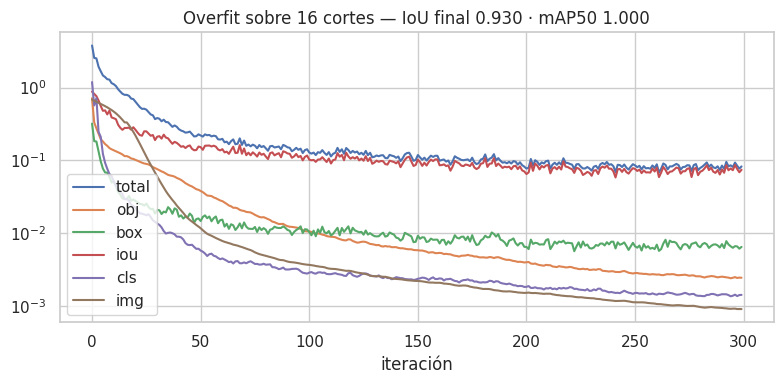

pérdida inicial → final: 3.7772 → 0.08256 | {'IoU': 0.929666317999363, 'mAP50': 1.0, 'mAP50_95': 0.8949346747002997}


In [ ]:
Xtr, Btr, _ = CACHE["train"]
idx = [i for i, b in enumerate(Btr) if len(b) == NC]
idx = list(np.random.default_rng(SEED).choice(idx, BATCH, replace=False))
of_loader = DataLoader(torch.utils.data.Subset(ds["train"], idx), batch_size=BATCH, collate_fn=collate)

of_model = PengwinNet(prior=PRIOR).to(DEVICE)
opt = torch.optim.Adam(of_model.parameters(), lr=1e-3)
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
hist = [run_epoch(of_model, of_loader, opt, scaler) for _ in tqdm(range(OVERFIT_ITERS), desc="overfit")]
hist = pd.DataFrame(hist)

of_sum, _ = evaluate(*predict(of_model, of_loader))
fig, ax = plt.subplots(figsize=(8, 4))
hist[["total", "obj", "box", "iou", "cls", "img"]].plot(logy=True, ax=ax)
ax.set_title(f"Overfit sobre {BATCH} cortes — IoU final {of_sum['IoU']:.3f} · mAP50 {of_sum['mAP50']:.3f}")
ax.set_xlabel("iteración"); plt.tight_layout(); plt.show()
print("pérdida inicial → final:", round(hist.total.iloc[0], 4), "→", round(hist.total.iloc[-1], 5), "|", of_sum)

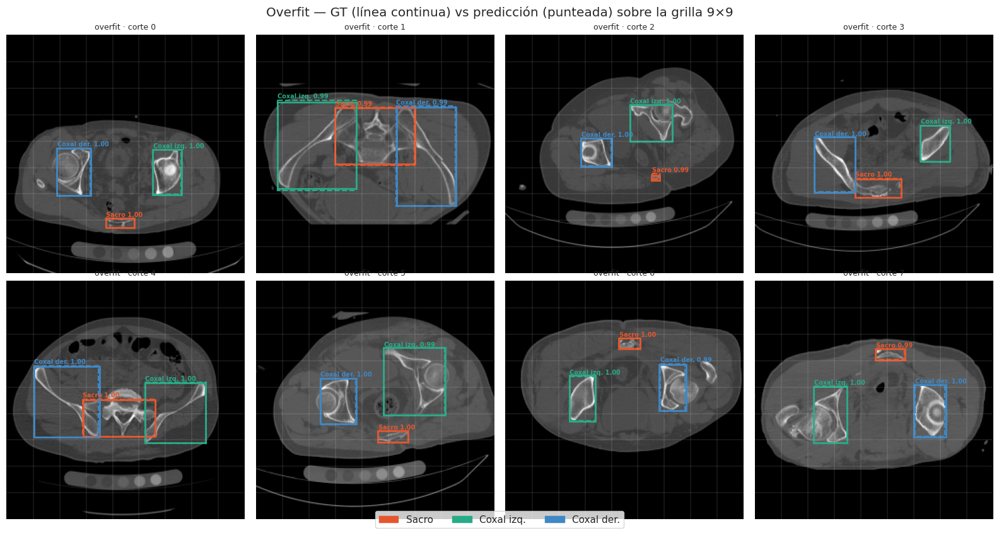

In [ ]:
def draw_preds(ax, img, gt, pred, title=""):
    ax.imshow(img, cmap="gray")
    for x0, y0, x1, y1, c in gt:
        ax.add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=REGION_COLORS[int(c) + 1], lw=2))
    for x0, y0, x1, y1, s, c in pred.tolist():
        col = REGION_COLORS[int(c) + 1]
        ax.add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=col, lw=1.6, ls="--"))
        ax.text(x0, y0 - 2, f"{REGIONS[int(c)+1]} {s:.2f}", color=col, fontsize=7, weight="bold")
    for k in range(1, S): ax.axhline(k * TARGET_SIZE / S, c="w", lw=.3, alpha=.4); ax.axvline(k * TARGET_SIZE / S, c="w", lw=.3, alpha=.4)
    ax.set_title(title, fontsize=9); ax.axis("off")

P_of, G_of = predict(of_model, of_loader, conf_thr=0.3)
fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))
for a, i in zip(axes.flat, range(8)):
    draw_preds(a, Xtr[idx[i]], G_of[i], P_of[i], f"overfit · corte {i}")
fig.legend(handles=[mpatches.Patch(color=REGION_COLORS[r], label=REGIONS[r]) for r in REGIONS], loc="lower center", ncol=3)
plt.suptitle("Overfit — GT (línea continua) vs predicción (punteada) sobre la grilla 9×9"); plt.tight_layout(); plt.show()

## 16. Entrenamiento completo (primeras predicciones)

AdamW + *cosine annealing*, precisión mixta (`torch.cuda.amp`), checkpoint por mejor IoU de validación.

ep 01 | train 0.6979 | val 0.7039 | IoU 0.674 | mAP50 0.754 | mAP50-95 0.347 | 99s
ep 02 | train 0.3539 | val 0.6123 | IoU 0.711 | mAP50 0.784 | mAP50-95 0.402 | 94s
ep 03 | train 0.2680 | val 0.5912 | IoU 0.727 | mAP50 0.809 | mAP50-95 0.434 | 95s
ep 04 | train 0.2234 | val 0.5807 | IoU 0.718 | mAP50 0.799 | mAP50-95 0.408 | 93s
ep 05 | train 0.1922 | val 0.5878 | IoU 0.737 | mAP50 0.821 | mAP50-95 0.452 | 92s
ep 06 | train 0.1675 | val 0.5843 | IoU 0.737 | mAP50 0.815 | mAP50-95 0.460 | 92s
ep 07 | train 0.1494 | val 0.5715 | IoU 0.737 | mAP50 0.816 | mAP50-95 0.451 | 91s
ep 08 | train 0.1307 | val 0.5776 | IoU 0.738 | mAP50 0.809 | mAP50-95 0.454 | 91s
ep 09 | train 0.1119 | val 0.6035 | IoU 0.742 | mAP50 0.827 | mAP50-95 0.466 | 92s
ep 10 | train 0.0990 | val 0.6018 | IoU 0.739 | mAP50 0.820 | mAP50-95 0.467 | 90s
ep 11 | train 0.0845 | val 0.6196 | IoU 0.741 | mAP50 0.823 | mAP50-95 0.467 | 90s
ep 12 | train 0.0720 | val 0.6385 | IoU 0.739 | mAP50 0.821 | mAP50-95 0.468 | 91s
ep 1

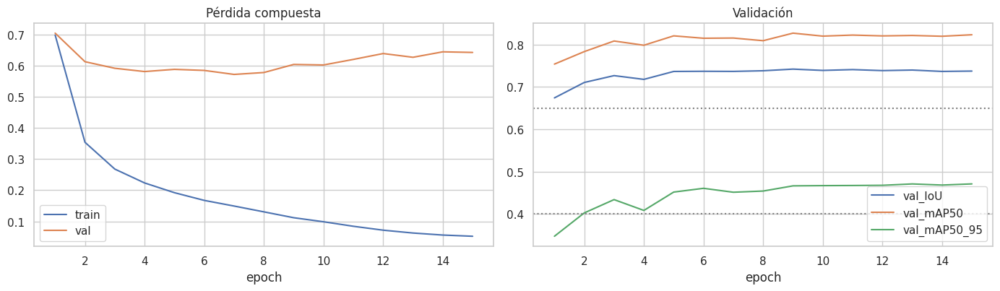

In [ ]:
model = PengwinNet(prior=PRIOR).to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=N_EPOCHS)
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
CKPT = OUT_DIR.parent / "s9_det_best.pth"; best, log = -1, []

for ep in range(1, N_EPOCHS + 1):
    t0 = time.time()
    tr = run_epoch(model, loaders["train"], opt, scaler, LAMBDA); sched.step()
    va = run_epoch(model, loaders["val"], lam=LAMBDA)
    summ, _ = evaluate(*predict(model, loaders["val"]))
    log.append(dict(epoch=ep, train=tr["total"], val=va["total"], **{f"val_{k}": v for k, v in summ.items()}))
    if summ["IoU"] > best:
        best = summ["IoU"]
        torch.save(dict(model=model.state_dict(), lam=LAMBDA, S=S, nout=NOUT, epoch=ep, val=summ), CKPT)
    print(f"ep {ep:02d} | train {tr['total']:.4f} | val {va['total']:.4f} | IoU {summ['IoU']:.3f} | "
          f"mAP50 {summ['mAP50']:.3f} | mAP50-95 {summ['mAP50_95']:.3f} | {time.time()-t0:.0f}s")

log = pd.DataFrame(log).set_index("epoch"); log.to_csv(OUT_DIR / "s9_train_log.csv")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
log[["train", "val"]].plot(ax=ax[0], title="Pérdida compuesta")
log[["val_IoU", "val_mAP50", "val_mAP50_95"]].plot(ax=ax[1], title="Validación")
for y in (0.65, 0.40): ax[1].axhline(y, ls=":", c="gray")
plt.tight_layout(); plt.show()

In [ ]:
model.load_state_dict(torch.load(CKPT, map_location=DEVICE)["model"])
P_val, G_val = predict(model, loaders["val"])
summ, per_cls = evaluate(P_val, G_val)
print("Validación (mejor checkpoint):", {k: round(v, 3) for k, v in summ.items()},
      "| objetivos: IoU ≥ 0.65 · mAP50 ≥ 0.65 · mAP50-95 ≥ 0.40")
print(per_cls.round(3))

Validación (mejor checkpoint): {'IoU': 0.742, 'mAP50': 0.827, 'mAP50_95': 0.466} | objetivos: IoU ≥ 0.65 · mAP50 ≥ 0.65 · mAP50-95 ≥ 0.40
              IoU   AP50  AP50_95
Sacro       0.615  0.620    0.280
Coxal izq.  0.782  0.942    0.570
Coxal der.  0.787  0.920    0.549


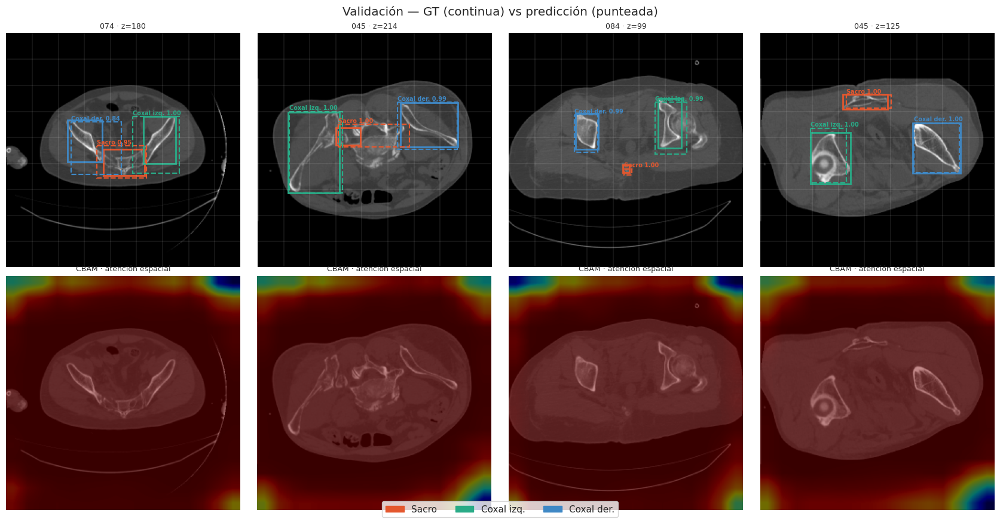

In [ ]:
# Primeras predicciones sobre validación + mapa de atención espacial del CBAM
Xva, Bva, Mva = CACHE["val"]
P_show, _ = predict(model, loaders["val"], conf_thr=0.3)
pick = [i for i, b in enumerate(Bva) if len(b) == NC]
pick = list(np.random.default_rng(1).choice(pick, 4, replace=False))
fig, axes = plt.subplots(2, 4, figsize=(17, 8.8))
for k, i in enumerate(pick):
    draw_preds(axes[0, k], Xva[i], Bva[i], P_show[i], f"{Mva.case_id[i]} · z={Mva.z[i]}")
    model.eval()
    with torch.no_grad(): model(torch.from_numpy(Xva[i]).float().div(255)[None, None].to(DEVICE))
    sa = F.interpolate(model.cbam.last_sa, size=(TARGET_SIZE, TARGET_SIZE), mode="bilinear")[0, 0].cpu()
    axes[1, k].imshow(Xva[i], cmap="gray"); axes[1, k].imshow(sa, cmap="jet", alpha=.45)
    axes[1, k].set_title("CBAM · atención espacial", fontsize=9); axes[1, k].axis("off")
fig.legend(handles=[mpatches.Patch(color=REGION_COLORS[r], label=REGIONS[r]) for r in REGIONS], loc="lower center", ncol=3)
plt.suptitle("Validación — GT (continua) vs predicción (punteada)"); plt.tight_layout(); plt.show()

In [ ]:
# Latencia por imagen (requisito 4.3): GPU y CPU
@torch.no_grad()
def latency_ms(m, device, n=50, warmup=10):
    m = m.to(device).eval(); x = torch.rand(1, 1, TARGET_SIZE, TARGET_SIZE, device=device)
    for _ in range(warmup): postprocess(m(x)["det"])
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(n): postprocess(m(x)["det"])
    if device.type == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t0) / n * 1000

lat = {"CPU": latency_ms(model, torch.device("cpu"))}
if torch.cuda.is_available(): lat["GPU"] = latency_ms(model, torch.device("cuda"))
model.to(DEVICE)
print({k: f"{v:.1f} ms/imagen" for k, v in lat.items()})

{'CPU': '51.0 ms/imagen', 'GPU': '3.6 ms/imagen'}


## 17. Pendientes para la semana 10
- Correr la ablación con/sin CBAM y con/sin pesos preentrenados (`PengwinNet(use_cbam=False)`).
- Cabeza de **segmentación de instancia** sobre `feat` (16×16) con decoder: semántica (3 regiones) + instancia por región.
- Ajuste fino de λ y del umbral de confianza; métricas sobre **test**.

---
# PENGWIN — Semana 10: pipeline completo 2.5D/3D → detección → NMS → segmentación de instancia → clasificación por pertenencia

**Requisito del avance (consigna, sección 6):** pipeline completo *detección → NMS → segmentación de instancia → clasificación por pertenencia*; entrenamiento completo; medición de la distancia de separación; comparación contra SAM; métricas de la sección 5.

Antes del código se responde a la retroalimentación de la entrega anterior. Sobre la **claridad conceptual**, el profesor preguntó por el **costo de la pérdida compuesta** y por **cómo está montado el modelo**. Además, en la última clase (segmentación con U-Net, Mask R-CNN, YOLO y SAM) dio cuatro recomendaciones:
1. El modelo no se puede ajustar a ciertos cortes.
2. Debe ser 3D, es decir, recorrer N cortes.
3. Debe usar *data augmentation* de recorte y *flip*.
4. Debe incluir cambios de color.

## 18. Qué llevamos y cómo está montado el modelo

### 18.1 Lo construido en S8–S9
| Semana | Qué se hizo | Por qué |
|---|---|---|
| S8 | Carga MHA/NIfTI con espaciado del header, ventana ósea (400/1800 HU), EDA, distancia GT con `distance_transform_edt`, splits **por paciente** (35/7/8), Visualizador 1 (MIP) | Sin fuga entre cortes del mismo paciente; toda medida en mm |
| S9 | FundidoraPC + CBAM + cabeza de detección en grilla 9×9 propia, IoU y NMS propios, overfit de un batch (IoU 0.93, mAP50 1.0) y primer entrenamiento (val: IoU 0.72, mAP50 0.82, mAP50-95 0.44) | La grilla 9×9 es la más gruesa con 0 % de colisiones (sección 11) |

### 18.2 Arquitectura S10: un backbone, un CBAM y tres cabezas
```
Entrada: N = 5 cortes vecinos a distancia física fija (z−4, z−2, z, z+2, z+4 mm) → 5×256×256, ventana ósea en [0, 1]
   │
   ▼  Stem 3D: Conv3d 3×3×3 (1→8) → Conv3d 5×1×1 (8→3), que colapsa z;  + atajo: corte central repetido ×3
 3×256×256      (con la última conv en cero, el stem arranca idéntico al modelo 2D de la S9)
   │
   ▼  FundidoraPC (Taller 3): 4 × [conv3×3 → BN → ReLU → maxpool 2]
 f1 32×128×128 → f2 64×64×64 → f3 128×32×32 → f4 256×16×16
   │
   ▼  CBAM (atención de canal → atención espacial) sobre f4   ← punto de bifurcación
   ├─► Cabeza 1 · CLASIFICACIÓN: GAP → Linear(256→3) → ¿Sacro / Coxal izq. / Coxal der. presentes? (multietiqueta)
   ├─► Cabeza 2 · DETECCIÓN: conv s2 p2 (16→9) → conv → 8×9×9 = [obj, x, y, w, h, 3 clases] → decodificación → NMS propio
   └─► Cabeza 3 · SEGMENTACIÓN: decoder tipo U-Net 16→32→64→128→256 con skips (f3, f2, f1, stem)
                → 4 canales semánticos (fondo + 3 regiones) + «fragmento principal» + «frontera de fractura»
```

### 18.3 Las dos etapas, como en el challenge
**Etapa 1, región anatómica.** La detección con NMS deja como máximo una caja por región en cada corte. La máscara semántica de la clase *c* se conserva solo dentro de la caja de la clase *c*. Así, la detección actúa como la ROI de la segmentación.

**Etapa 2, fragmentos dentro de cada región.** Solo dentro de la máscara de la región se hace lo siguiente:
1. Se separan el fragmento principal y los demás fragmentos.
2. Se cortan los fragmentos por las fronteras de fractura predichas.
3. Se etiquetan **componentes conexas en 3D** sobre el volumen apilado.

Cada fragmento hereda el color de su región; esa es la *clasificación por pertenencia*. No se usa Mask R-CNN ni YOLO: las tres cabezas, la grilla, el NMS y el postproceso son implementación propia. Mask R-CNN solo aporta la idea de dos etapas (primero la región, después la instancia), como permite la sección 4.1.

### 18.4 ¿Es costosa la pérdida compuesta?
No, y la razón es estructural:
- **Un forward y un backward, sin importar cuántos términos haya.** $\mathcal L=\sum_k\lambda_k\mathcal L_k$ es una suma. Autograd la recorre **una vez** y el gradiente de la suma es la suma de los gradientes. Lo caro es propagar por el backbone y el decoder, y eso ocurre una sola vez por iteración aunque haya 5 o 9 términos.
- **Los términos de detección operan sobre un tensor diminuto.** Son 8×9×9 = 648 números por corte. IoU, L1 y CE se evalúan solo en las ~2–3 celdas positivas (son máscaras booleanas, no bucles). En comparación, el backbone procesa 65 536 píxeles × 4 etapas convolucionales.
- **λ se calibra una sola vez, antes de entrenar.** Son unas pocas pasadas sin optimizador, no un costo por época.
- **Medición (sección 23):** se cronometran por separado el *forward* del modelo, el cálculo de la pérdida y el *backward*. La pérdida es una fracción pequeña del paso, y eso queda como evidencia.

### 18.5 Recomendaciones del profesor → decisiones
| Recomendación | Decisión en S10 | Justificación con el EDA |
|---|---|---|
| «No ajustarse a ciertos cortes» | Se entrena, valida e infiere sobre **todos los cortes** de cada volumen. En la S9 solo se usaban los cortes con hueso más un 10 % de negativos. | Antes, la distribución de entrenamiento no era la de inferencia (un volumen completo trae ~25 % de cortes sin hueso) y el modelo nunca veía bien los extremos craneal y caudal |
| «Modelo 3D que recorra N cortes» | **2.5D con stem Conv3d**: N = 5 cortes a 2 mm de separación física → convolución 3D → 3 canales para la FundidoraPC. Más **consistencia 3D** en inferencia: suavizado de probabilidades en z, componentes conexas 3D y EDT 3D en mm | El espaciado en z varía entre 0.625 y 1.25 mm, así que los vecinos se eligen en mm y no en índices. Una U-Net 3D completa con 35 volúmenes no cabe en el cómputo de la consigna (256 px, batch 8–16) y perdería el transfer learning 2D del backbone |
| *Flip* | *Flip* horizontal **intercambiando las etiquetas izq. ↔ der.** | Al espejar la imagen, el coxal izquierdo queda donde estaba el derecho. Sin el intercambio, el *flip* enseñaría lateralidad errónea |
| *Cut* (recorte) | *Random resized crop* (80–100 %) + *cutout* (un parche borrado) | Variación de escala y FOV (mm/px entre 1.2 y 1.95 según el EDA) y robustez a oclusión parcial |
| Cambios de color | En CT con un solo canal, el «color» es la intensidad: contraste, brillo, gamma y ruido gaussiano, equivalentes a variar la ventana HU | Solo se aplican a la imagen; las transformaciones geométricas se aplican por igual a imagen y máscara |
| Familias vistas en clase | U-Net → cabeza 3 · Mask R-CNN → solo la idea de dos etapas · YOLO → **prohibido**; la cabeza en grilla es propia, sin anchors · SAM → baseline *zero-shot* (sección 28) | Sección 4.1 de la consigna |

## 19. Configuración de la semana 10

In [ ]:
import copy, gc
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import f1_score, roc_auc_score, confusion_matrix

N_CTX        = 5          # cortes de contexto que recorre el modelo
CTX_MM       = 2.0        # separación física entre cortes de contexto [mm]
BATCH10      = 16
EPOCHS10     = 12         # con 100 casos cada época tiene el doble de iteraciones (≈ 24 épocas de antes)
RETRAIN10    = False      # False: si existe outputs/s10_best.pth en Drive se carga en vez de reentrenar
LR10         = 1e-3
CONF_OP      = 0.30       # umbral de operación del detector (pipeline); para mAP se usa 0.05
GATE_MARGIN  = 6          # px de holgura alrededor de la caja al recortar la máscara semántica
MIN_FRAG_MM3 = 250        # valor inicial; el definitivo se calibra en validación (sección 26.1)
DIST_MIN_IOU = 0.25       # un conminuto solo se «mide» si su pareja predicha tiene IoU 3D ≥ este valor
FUSION_FRAC  = 0.50       # ≥ 50 % del conminuto GT cae dentro del principal predicho → «fusionado»
NSEG         = NC + 1     # fondo + 3 regiones
AUG = dict(p_flip=0.5, p_crop=0.5, crop=(0.80, 1.0), p_cut=0.5, cut_frac=0.15,
           contrast=0.15, bright=0.08, gamma=(0.8, 1.25), noise=0.02)

def amp():   # precisión mixta (mecanismo torch.cuda.amp, API unificada torch.autocast)
    return torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP)

for k in ("CACHE", "ds", "loaders", "of_loader", "of_model", "Xtr", "Xva"):   # libera la caché 2D de la S9
    globals().pop(k, None)
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()

# Transfer learning SOLO en el backbone (sección 4.1): pesos de la FundidoraPC del Taller 3, si se guardaron.
TALLER3_CKPT  = OUT_ROOT / "fundidora_taller3.pth"           # súbanlo a MyDrive/PENGWIN_outputs (ajustar el nombre)
BACKBONE_CKPT = str(TALLER3_CKPT) if TALLER3_CKPT.exists() else None
print("transfer learning del backbone:", BACKBONE_CKPT or "NO (no se encontraron los pesos del Taller 3 → se declara en el informe)")

transfer learning del backbone: NO (no se encontraron los pesos del Taller 3 → se declara en el informe)


## 20. Caché volumétrica: **todos** los cortes de cada caso
Se guarda cada volumen completo ya llevado a 256×256 (ventana ósea → *padding* a cuadrado → resize). La imagen se interpola de forma bilineal y la etiqueta de fragmento por vecino más cercano. Por cada caso se guardan además:
- `rlut`: fragmento → región.
- `mlut`: fragmento → ¿es el principal? Se toma el de mayor volumen 3D, igual que en el EDA.
- El espaciado remuestreado `sp_rs`, que se usa para medir en mm.

Las regiones, el principal, las fronteras y las cajas se derivan **después** del *augmentation*, de modo que las etiquetas siempre corresponden a la imagen transformada.

In [ ]:
def region_lut(scheme):
    lut = np.zeros(256, np.uint8)
    for r, (lo, hi) in LABEL_SCHEMES[scheme].items(): lut[lo:hi + 1] = r
    return lut

MAIN_LABELS = frags[frags.is_main].groupby("case_id").label.apply(set).to_dict()

def to_grid_stack(vol, pad, size, mode, fn=None, chunk=48):
    out = []
    for i in range(0, len(vol), chunk):
        a = vol[i:i + chunk]
        a = fn(a) if fn is not None else a.astype(np.float32)
        t = torch.from_numpy(np.pad(a, pad))[:, None].float()
        kw = dict(align_corners=False) if mode == "bilinear" else {}
        out.append(F.interpolate(t, size=(size, size), mode=mode, **kw)[:, 0])
    return torch.cat(out)

def prep_volume(case_id, size=TARGET_SIZE):
    c = cases.set_index("case_id").loc[case_id]
    img, meta, _ = load_volume(c.image, np.int16)
    lab, _, _    = load_volume(c.label, np.int16)
    scheme = detect_scheme(lab.max()); rlut = region_lut(scheme)
    lab = np.where(rlut[np.clip(lab, 0, 255)] > 0, lab, 0)            # fémur (2026) → fondo
    nz, ny, nx = img.shape; side = max(ny, nx)
    py, px = (side - ny) // 2, (side - nx) // 2
    pad = ((0, 0), (py, side - ny - py), (px, side - nx - px))
    x = to_grid_stack(img, pad, size, "bilinear", fn=lambda a: window_hu(a, **WINDOW))
    x = (x.clamp(0, 1) * 255).round().to(torch.uint8).numpy()
    ins = to_grid_stack(lab, pad, size, "nearest-exact").round().to(torch.uint8).numpy()
    mlut = np.zeros(256, bool); mlut[list(MAIN_LABELS.get(case_id, []))] = True
    sp = meta["spacing_zyx"]; scale = size / side
    return dict(x=x, ins=ins, rlut=rlut, mlut=mlut, sp=sp, scale=scale, pad=(py, px), shape=img.shape,
                sp_rs=(sp[0], sp[1] / scale, sp[2] / scale))      # mm/vóxel en el espacio de 256 px

ALL_IDS = splits["train"] + splits["val"] + splits["test"]
VOL = {cid: prep_volume(cid) for cid in tqdm(ALL_IDS, desc="volúmenes")}
mem = sum(v["x"].nbytes + v["ins"].nbytes for v in VOL.values()) / 1e9
for k in ("train", "val", "test"):
    nz = sum(len(VOL[c]["x"]) for c in splits[k])
    nb = sum(VOL[c]["rlut"][VOL[c]["ins"]].reshape(len(VOL[c]["x"]), -1).any(1).sum() for c in splits[k])
    print(f"{k:5s}: {len(splits[k]):2d} casos | {nz:5d} cortes (todos) | {nz - nb:5d} sin hueso ({(nz - nb) / nz * 100:.1f} %)")
print(f"memoria de la caché: {mem:.2f} GB")

volúmenes:   0%|          | 0/100 [00:00<?, ?it/s]

train: 70 casos | 22437 cortes (todos) |  5504 sin hueso (24.5 %)
val  : 15 casos |  4779 cortes (todos) |  1075 sin hueso (22.5 %)
test : 15 casos |  4890 cortes (todos) |  1219 sin hueso (24.9 %)
memoria de la caché: 4.21 GB


### 20.1 Estadísticos de la grilla y de las fronteras sobre *todos* los cortes de entrenamiento
Como ahora entran todos los cortes, cambian las celdas positivas por corte, y con ellas `pos_weight` y el *prior*. La fracción de píxeles de frontera dentro del hueso fija el `pos_weight` del canal de fronteras con el mismo criterio √(neg/pos) de la detección.

In [ ]:
SWAP_LR = torch.tensor([0, 1, 3, 2])      # flip horizontal: coxal izq. ↔ coxal der.

def seg_targets(ins, rlut, mlut, flip=False):
    # ins (H,W) long -> región (H,W) long, principal (H,W) float, frontera entre fragmentos (H,W) float
    reg = rlut[ins]
    if flip: reg = SWAP_LR[reg]
    main = (mlut[ins] & (reg > 0)).float()
    f = ins.float()[None, None]
    mx = F.max_pool2d(f, 3, 1, 1)[0, 0]
    mn = -F.max_pool2d(-torch.where(f > 0, f, torch.full_like(f, 1e4)), 3, 1, 1)[0, 0]
    bnd = ((ins > 0) & ((mx > ins) | (mn < ins))).float()     # vecino con OTRA etiqueta de fragmento
    return reg, main, bnd

def boxes_from_reg(reg):
    bz = []
    for r in REGIONS:
        m = reg == r
        if not m.any(): continue
        ys, xs = m.any(1).nonzero()[:, 0], m.any(0).nonzero()[:, 0]
        x0, y0, x1, y1 = xs[0].item(), ys[0].item(), xs[-1].item() + 1, ys[-1].item() + 1
        if min(x1 - x0, y1 - y0) < MIN_BOX_PX: continue
        bz.append([x0, y0, x1, y1, r - 1])
    return np.array(bz, np.float32).reshape(-1, 5)

n_box = n_sl = 0; bnd_pos = bone_px = 0
for cid in splits["train"]:
    v = VOL[cid]; rl = torch.from_numpy(v["rlut"].astype(np.int64)); ml = torch.from_numpy(v["mlut"])
    for z in range(0, len(v["x"])):
        ins = torch.from_numpy(v["ins"][z]).long(); n_sl += 1
        if not ins.any(): continue
        reg, _, bnd = seg_targets(ins, rl, ml)
        n_box += len(boxes_from_reg(reg))
        if z % 4 == 0: bnd_pos += bnd.sum().item(); bone_px += (reg > 0).sum().item()
POS_PER_IMG10 = n_box / n_sl
POS_W10 = math.sqrt((S * S - POS_PER_IMG10) / POS_PER_IMG10)
PRIOR10 = POS_PER_IMG10 / (S * S)
BND_FRAC = max(bnd_pos / max(bone_px, 1), 1e-4)
BND_PW = math.sqrt((1 - BND_FRAC) / BND_FRAC)
print(f"celdas positivas por corte: {POS_PER_IMG10:.2f} (S9, solo cortes con hueso: {POS_PER_IMG:.2f}) → pos_weight obj = {POS_W10:.2f}")
print(f"píxeles de frontera dentro del hueso: {BND_FRAC*100:.2f} % → pos_weight frontera = {BND_PW:.2f}")

celdas positivas por corte: 1.93 (S9, solo cortes con hueso: 2.48) → pos_weight obj = 6.40
píxeles de frontera dentro del hueso: 0.70 % → pos_weight frontera = 11.90


## 21. Dataset 2.5D y *data augmentation*
Para el corte *z* se apilan los cortes `z + round(k·2 mm / sp_z)` con k ∈ {−2, …, 2}. El orden de las operaciones es:
1. *Flip* (con intercambio izq./der.).
2. Recorte aleatorio reescalado a 256.
3. Contraste, brillo, gamma y ruido.
4. *Cutout*.

Las transformaciones geométricas se aplican a la imagen y a la etiqueta de fragmento (por vecino más cercano). Las fotométricas solo a la imagen. Validación y prueba van **sin** augmentation.

In [ ]:
def ctx_index(nz, z, sp_z, n=N_CTX, mm=CTX_MM):
    offs = np.round((np.arange(n) - n // 2) * mm / sp_z).astype(int)
    return np.clip(z + offs, 0, nz - 1)

def augment(x, ins, rng):
    H = x.shape[-1]; flip = False
    if rng.random() < AUG["p_flip"]:                                              # flip
        x, ins, flip = x.flip(-1), ins.flip(-1), True
    if rng.random() < AUG["p_crop"]:                                              # cut: recorte + reescalado
        h = int(H * rng.uniform(*AUG["crop"])); y0, x0 = rng.integers(0, H - h + 1, 2)
        x = F.interpolate(x[None, :, y0:y0 + h, x0:x0 + h], size=(H, H), mode="bilinear", align_corners=False)[0]
        ins = F.interpolate(ins[None, None, y0:y0 + h, x0:x0 + h].float(), size=(H, H), mode="nearest-exact")[0, 0].long()
    c = 1 + rng.uniform(-AUG["contrast"], AUG["contrast"]); b = rng.uniform(-AUG["bright"], AUG["bright"])
    x = ((x - 0.5) * c + 0.5 + b).clamp(0, 1) ** rng.uniform(*AUG["gamma"])      # «color»: contraste/brillo/gamma
    x = (x + torch.randn_like(x) * AUG["noise"] * rng.random()).clamp(0, 1)        # ruido
    if rng.random() < AUG["p_cut"]:                                               # cutout (solo imagen)
        h = max(2, int(H * AUG["cut_frac"] * rng.uniform(0.5, 1))); y0, x0 = rng.integers(0, H - h, 2)
        x = x.clone(); x[:, y0:y0 + h, x0:x0 + h] = 0
    return x.contiguous(), ins.contiguous(), flip

class VolSliceDS(Dataset):
    def __init__(self, ids, train=False, n_ctx=N_CTX):
        self.train, self.n_ctx = train, n_ctx
        self.index = [(cid, z) for cid in ids for z in range(len(VOL[cid]["x"]))]
        self.lut = {cid: (torch.from_numpy(VOL[cid]["rlut"].astype(np.int64)), torch.from_numpy(VOL[cid]["mlut"])) for cid in ids}
    def __len__(self): return len(self.index)
    def __getitem__(self, i):
        cid, z = self.index[i]; v = VOL[cid]
        x = torch.from_numpy(v["x"][ctx_index(len(v["x"]), z, v["sp"][0], self.n_ctx)]).float().div_(255)
        ins = torch.from_numpy(v["ins"][z]).long(); flip = False
        if self.train:
            x, ins, flip = augment(x, ins, np.random.default_rng(torch.randint(0, 2**31 - 1, (1,)).item()))
        reg, main, bnd = seg_targets(ins, *self.lut[cid], flip)
        b = boxes_from_reg(reg)
        tgt, cls_map, _ = encode_target(b)
        pres = torch.zeros(NC); pres[b[:, 4].astype(int)] = 1
        return x, tgt, cls_map, pres, reg, main, bnd, b

def collate10(batch):
    *t, g = zip(*batch)
    return [torch.stack(a) for a in t] + [list(g)]

def make_loaders(n_ctx=N_CTX, train_ids=None):
    g = torch.Generator().manual_seed(SEED)
    ids = dict(train=list(train_ids) if train_ids is not None else splits["train"], val=splits["val"], test=splits["test"])
    return {k: DataLoader(VolSliceDS(ids[k], train=(k == "train"), n_ctx=n_ctx), batch_size=BATCH10,
                          shuffle=(k == "train"), collate_fn=collate10, generator=g, num_workers=2,
                          pin_memory=DEVICE.type == "cuda", persistent_workers=False) for k in ("train", "val", "test")}
loaders10 = make_loaders()
print({k: len(l.dataset) for k, l in loaders10.items()}, "cortes")

{'train': 22437, 'val': 4779, 'test': 4890} cortes


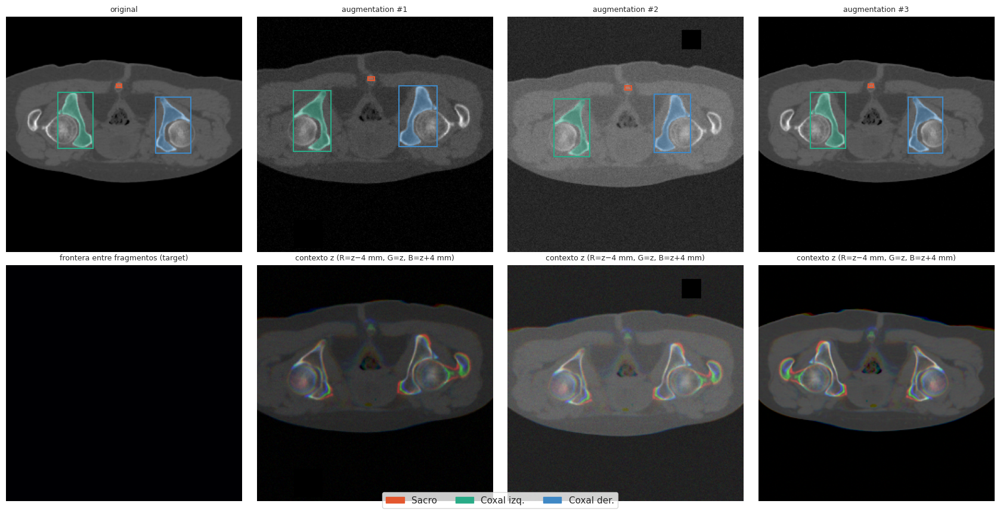

In [ ]:
# Verificación visual del augmentation: el flip debe intercambiar los colores izq./der.
def show_mask(ax, img, reg, boxes=None, title=""):
    ax.imshow(img, cmap="gray"); rgba = np.zeros((*reg.shape, 4))
    for r, col in REGION_COLORS.items():
        rgba[reg == r] = [*[int(col[i:i + 2], 16) / 255 for i in (1, 3, 5)], .45]
    ax.imshow(rgba)
    for x0, y0, x1, y1, c in (boxes if boxes is not None else []):
        ax.add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=REGION_COLORS[int(c) + 1], lw=1.5))
    ax.set_title(title, fontsize=9); ax.axis("off")

dtr = loaders10["train"].dataset
i0 = next(i for i, (c, z) in enumerate(dtr.index) if len(boxes_from_reg(seg_targets(torch.from_numpy(VOL[c]["ins"][z]).long(), *dtr.lut[c])[0])) == NC)
dtr.train = False; x0_, *_, reg0, m0_, b0_, bx0 = dtr[i0]; dtr.train = True
fig, ax = plt.subplots(2, 4, figsize=(17, 8.6))
show_mask(ax[0, 0], x0_[N_CTX // 2], reg0, bx0, "original")
ax[1, 0].imshow(b0_, cmap="magma"); ax[1, 0].set_title("frontera entre fragmentos (target)", fontsize=9); ax[1, 0].axis("off")
torch.manual_seed(3)
for k in range(1, 4):
    x_, *_, reg_, _, bnd_, bx_ = dtr[i0]
    show_mask(ax[0, k], x_[N_CTX // 2], reg_, bx_, f"augmentation #{k}")
    ax[1, k].imshow(x_.permute(1, 2, 0)[..., [0, N_CTX // 2, -1]].numpy()); ax[1, k].axis("off")
    ax[1, k].set_title(f"contexto z (R=z−{CTX_MM*2:.0f} mm, G=z, B=z+{CTX_MM*2:.0f} mm)", fontsize=9)
fig.legend(handles=[mpatches.Patch(color=REGION_COLORS[r], label=REGIONS[r]) for r in REGIONS], loc="lower center", ncol=3)
plt.tight_layout(); plt.show()

## 22. Modelo de la semana 10
`Stem3D` convierte la pila de N cortes en 3 canales para que la primera capa de la FundidoraPC reciba lo mismo que en el Taller 3 (RGB). Así el *transfer learning* del backbone sigue siendo válido. La última Conv3d se inicializa en **cero**: al arrancar, la salida del stem es el corte central repetido, de modo que el modelo parte exactamente del 2D de la S9 y **aprende** cuánto contexto en z necesita.

In [ ]:
class Stem3D(nn.Module):
    def __init__(self, n=N_CTX, mid=8):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv3d(1, mid, 3, padding=1, bias=False), nn.BatchNorm3d(mid), nn.ReLU(inplace=True),
                                  nn.Conv3d(mid, 3, (n, 1, 1)))                   # colapsa la profundidad z
        nn.init.zeros_(self.conv[-1].weight); nn.init.zeros_(self.conv[-1].bias)
    def forward(self, x):                                                          # x (B, N, H, W)
        c = x.shape[1] // 2
        return x[:, c:c + 1].expand(-1, 3, -1, -1) + self.conv(x[:, None])[:, :, 0]

class Up(nn.Module):
    def __init__(self, ci, cs, co):
        super().__init__(); self.conv = nn.Sequential(conv_bn(ci + cs, co), conv_bn(co, co))
    def forward(self, x, skip):
        x = F.interpolate(x, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return self.conv(torch.cat([x, skip], 1))

class PengwinNet10(nn.Module):
    def __init__(self, use_cbam=True, ckpt=BACKBONE_CKPT, prior=None, bnd_prior=None, n_ctx=N_CTX):
        super().__init__()
        self.stem = Stem3D(n_ctx)
        self.backbone = load_fundidora(ckpt, in_channels=3); c = self.backbone.out_features
        w = [self.backbone.f1[0].out_channels, self.backbone.f2[0].out_channels, self.backbone.f3[0].out_channels]
        self.cbam = CBAM(c) if use_cbam else nn.Identity()
        self.cls_head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(c, NC))              # cabeza 1
        self.to_grid  = conv_bn(c, 256, k=3, s=2, p=2)                                                       # cabeza 2
        self.det_head = nn.Sequential(conv_bn(256, 256), nn.Conv2d(256, NOUT, 1))
        self.up3, self.up2 = Up(c, w[2], 128), Up(128, w[1], 64)                                             # cabeza 3
        self.up1, self.up0 = Up(64, w[0], 32), Up(32, 3, 16)
        self.seg_out = nn.Conv2d(16, NSEG + 2, 1)                     # 4 semánticos + principal + frontera
        if prior:     nn.init.constant_(self.det_head[-1].bias[0], -math.log((1 - prior) / prior))
        if bnd_prior: nn.init.constant_(self.seg_out.bias[NSEG + 1], -math.log((1 - bnd_prior) / bnd_prior))
    def forward(self, x):
        s = self.stem(x); b = self.backbone
        f1 = b.f1(s); f2 = b.f2(f1); f3 = b.f3(f2); f4 = self.cbam(b.f4(f3))
        d = self.up0(self.up1(self.up2(self.up3(f4, f3), f2), f1), s)
        seg = self.seg_out(d)
        return dict(det=self.det_head(self.to_grid(f4)), cls=self.cls_head(f4),
                    sem=seg[:, :NSEG], main=seg[:, NSEG], bnd=seg[:, NSEG + 1], feat=f4)

model10 = PengwinNet10(prior=PRIOR10, bnd_prior=BND_FRAC).to(DEVICE)
with torch.no_grad(): o = model10(torch.zeros(2, N_CTX, TARGET_SIZE, TARGET_SIZE, device=DEVICE))
print({k: tuple(v.shape) for k, v in o.items()})
n_par = lambda m: sum(p.numel() for p in m.parameters()) / 1e6
print(f"parámetros: total {n_par(model10):.2f} M | stem 3D {n_par(model10.stem)*1e3:.1f} k | backbone {n_par(model10.backbone):.2f} M | "
      f"CBAM {n_par(model10.cbam)*1e3:.1f} k | detección {n_par(model10.to_grid)+n_par(model10.det_head):.2f} M | "
      f"segmentación {sum(n_par(m) for m in (model10.up3, model10.up2, model10.up1, model10.up0, model10.seg_out)):.2f} M")

{'det': (2, 8, 9, 9), 'cls': (2, 3), 'sem': (2, 4, 256, 256), 'main': (2, 256, 256), 'bnd': (2, 256, 256), 'feat': (2, 256, 16, 16)}
parámetros: total 2.36 M | stem 3D 0.4 k | backbone 0.39 M | CBAM 8.3 k | detección 1.18 M | segmentación 0.78 M


## 23. Pérdida compuesta multitarea, calibración de λ y costo computacional

$\mathcal L = \underbrace{\lambda_{obj}\mathrm{BCE}_{obj}+\lambda_{box}L_1+\lambda_{iou}(1-\mathrm{IoU})+\lambda_{cls}\mathrm{CE}_{clase}}_{\text{detección}} + \underbrace{\lambda_{img}\mathrm{BCE}_{presencia}}_{\text{clasificación}} + \underbrace{\lambda_{ce}\mathrm{CE}_{sem}+\lambda_{dice}(1-\mathrm{Dice}_{sem})+\lambda_{main}\mathrm{BCE}_{principal}+\lambda_{bnd}\mathrm{BCE}_{frontera}}_{\text{segmentación}}$

**Lectura probabilística de cada término.** Cada término es la log-verosimilitud negativa de un supuesto sobre los datos:
- BCE: cada celda o píxel sigue una Bernoulli.
- CE: categórica.
- L1: error de Laplace, más robusta que L2 cuando las cajas iniciales están muy lejos.
- Presencia: BCE multietiqueta, porque en un corte pueden coexistir las 3 regiones.

**Pares complementarios.**
- **L1 + (1−IoU):** IoU es la métrica que se reporta y no depende de la escala, pero su gradiente es **cero** cuando las cajas no se solapan. L1 da señal en ese caso.
- **CE + Dice:** CE da gradientes estables por píxel. Dice optimiza el solapamiento y no se deja dominar por el ~98 % de fondo del EDA.

**Desbalance.** Se usa `pos_weight` = √(neg/pos) en objectness y en fronteras. El peso modifica el óptimo de la predicción: $q^*=\frac{w\,p}{w\,p+1-p}$. Para una celda vecina ambigua con $p\approx0.05$:
- con $w$ = neg/pos ≈ 30, $q^*\approx0.6$, que supera el umbral de 0.3 y produce un **falso positivo**;
- con $w=\sqrt{\cdot}\approx5.6$, $q^*\approx0.23$, por debajo del umbral.

Los términos de máscara de principal y frontera se promedian solo sobre píxeles de hueso; los de caja y clase, solo sobre celdas positivas.

**Calibración de λ (versión corregida).** En la S9 se igualaban los **valores** iniciales $L_k^{(0)}$. Eso no iguala la contribución al gradiente, que depende de la derivada y no del valor; además, los términos tienen unidades distintas (nats, px relativos, IoU adimensional). Ahora se mide la **norma del gradiente de cada término** sobre los parámetros que comparten las tres cabezas (stem 3D + FundidoraPC + CBAM): $g_k=\lVert\nabla_{\theta_{comp}}\mathcal L_k\rVert$. No basta con la última capa, porque la segmentación también llega al tronco por los *skips* (f1–f3). Se promedia en 8 batches y se fija $\lambda_k=\bar g/g_k$ (recortado a [0.05, 20]). Así, cada tarea empuja el backbone compartido con la misma fuerza al inicio; es la idea de GradNorm (Chen et al., 2018) aplicada una sola vez. Se reportan ambas calibraciones para compararlas.

**¿Por qué importa medir en el tronco compartido?** Con Adam, cada parámetro se normaliza por la magnitud de su propio gradiente. Por eso multiplicar por λ un término que solo toca su propia cabeza casi no cambia nada. λ decide el reparto **donde se suman los gradientes de varias tareas**, y ese lugar es el backbone compartido.

**Términos que tocan el límite del recorte.** En la calibración, `img` (presencia) y `sem_dice` quedan en λ = 20, el techo. No es un error, se explica así:
- La cabeza de presencia es `GAP → Linear` sobre f4: el gradiente que devuelve al tronco pasa por un promedio global de 16×16 posiciones, de modo que su norma es ~10–100 veces menor que la de las cabezas densas.
- El Dice suave se calcula agregando todo el batch, y el gradiente de cada píxel se divide entre el denominador (suma de áreas), así que también es pequeño en el tronco.

Igualar por completo sus normas exigiría λ ≈ 100. Eso amplificaría en el backbone una señal débil y ruidosa e inestabilizaría el entrenamiento en fp16 (precisión mixta). El recorte a [0.05, 20] es la decisión explícita de **acercar** su aporte sin dejar que dominen. El resultado se valida en métricas: F1 de presencia ≥ 0.97 y Dice semántico ≥ 0.95 en validación indican que ambos términos sí aprenden.

In [ ]:
def loss_parts(out, tgt, cls_map, pres, reg, main, bnd):
    det = out["det"].float(); pos = tgt[:, 0] > 0; dev = det.device
    P = dict(obj=F.binary_cross_entropy_with_logits(det[:, 0], tgt[:, 0], pos_weight=torch.tensor(POS_W10, device=dev)),
             img=F.binary_cross_entropy_with_logits(out["cls"].float(), pres))
    if pos.any():
        p_xywh = det[:, 1:5].sigmoid()
        P["box"] = F.l1_loss(p_xywh.permute(0, 2, 3, 1)[pos], tgt[:, 1:5].permute(0, 2, 3, 1)[pos])
        pb, tb = cell_to_xyxy(p_xywh)[pos], cell_to_xyxy(tgt[:, 1:5])[pos]
        P["iou"] = (1 - torch.diagonal(box_iou(pb, tb))).mean()
        P["cls"] = F.cross_entropy(det[:, 5:].permute(0, 2, 3, 1)[pos], cls_map[pos])
    else:
        z = det.sum() * 0; P.update(box=z, iou=z, cls=z)
    sem = out["sem"].float(); bone = (reg > 0).float()
    P["sem_ce"] = F.cross_entropy(sem, reg)
    p = sem.softmax(1)[:, 1:]; t = F.one_hot(reg, NSEG).permute(0, 3, 1, 2)[:, 1:].float()
    inter, den = (p * t).sum((0, 2, 3)), p.sum((0, 2, 3)) + t.sum((0, 2, 3))
    P["sem_dice"] = 1 - ((2 * inter + 1) / (den + 1)).mean()
    def masked_bce(logit, y, pw=None):
        l = F.binary_cross_entropy_with_logits(logit, y, reduction="none", pos_weight=pw)
        return (l * bone).sum() / bone.sum().clamp(min=1)
    P["main"] = masked_bce(out["main"].float(), main)
    P["bnd"]  = masked_bce(out["bnd"].float(), bnd, torch.tensor(BND_PW, device=dev))
    return P

TERMS = ["obj", "box", "iou", "cls", "img", "sem_ce", "sem_dice", "main", "bnd"]

def to_dev(batch):
    return [b.to(DEVICE, non_blocking=True) for b in batch[:-1]] + [batch[-1]]

def calibrate_lambdas10(model, loader, n_batches=8, clip=(0.05, 20.)):
    state = copy.deepcopy(model.state_dict()); model.train()
    shared = [p for mod in (model.stem, model.backbone, model.cbam) for p in mod.parameters() if p.dim() > 1]
    G = {k: 0. for k in TERMS}; V = {k: 0. for k in TERMS}; it = iter(loader); t0 = time.perf_counter()
    for _ in range(n_batches):
        x, tgt, cm, pres, reg, main, bnd, _ = to_dev(next(it))
        parts = loss_parts(model(x), tgt, cm, pres, reg, main, bnd)
        for k in TERMS:
            gr = torch.autograd.grad(parts[k], shared, retain_graph=True, allow_unused=True)
            G[k] += math.sqrt(sum((g.float() ** 2).sum().item() for g in gr if g is not None)) / n_batches
            V[k] += parts[k].item() / n_batches
    model.load_state_dict(state)
    secs = time.perf_counter() - t0
    gm, vm = np.mean([G[k] for k in TERMS if G[k] > 0]), np.mean(list(V.values()))
    lam_g = {k: float(np.clip(gm / max(G[k], 1e-8), *clip)) for k in TERMS}
    lam_v = {k: float(np.clip(vm / max(V[k], 1e-8), *clip)) for k in TERMS}
    tab = pd.DataFrame(dict(L0=V, grad_norm=G, lambda_valor_S9=lam_v, lambda_gradiente_S10=lam_g)).round(4)
    return lam_g, tab, secs

LAMBDA10, lam_tab, cal_s = calibrate_lambdas10(model10, loaders10["train"])
display(lam_tab)
print(f"calibración: {cal_s:.1f} s, una sola vez antes de entrenar")
sat = [k for k, v in LAMBDA10.items() if v >= 20 - 1e-6 or v <= 0.05 + 1e-6]
print("términos en el límite del recorte [0.05, 20]:", sat or "ninguno")

,L0,grad_norm,lambda_valor_S9,lambda_gradiente_S10
obj,0.5542,2.7740,1.3992,1.6192
box,0.2488,1.9527,3.1168,2.3003
iou,0.7798,3.1292,0.9945,1.4354
cls,1.2448,14.3396,0.6230,0.3132
img,0.6931,0.1916,1.1188,20.0000
sem_ce,1.2743,1.7883,0.6086,2.5117
sem_dice,0.9871,0.1300,0.7856,20.0000
main,0.8332,11.1175,0.9307,0.4040
bnd,0.3639,5.0023,2.1310,0.8979


calibración: 11.5 s, una sola vez antes de entrenar
términos en el límite del recorte [0.05, 20]: ['img', 'sem_dice']


In [ ]:
# Costo computacional: forward del modelo vs cálculo de la pérdida vs backward
def profile_step(model, loader, lam, n=15):
    model.train(); opt_ = torch.optim.SGD(model.parameters(), lr=0.)
    sync = (lambda: torch.cuda.synchronize()) if DEVICE.type == "cuda" else (lambda: None)
    T = dict(forward=0., perdida=0., backward=0.); it = iter(loader)
    for i in range(n + 3):
        x, tgt, cm, pres, reg, main, bnd, _ = to_dev(next(it)); sync()
        t0 = time.perf_counter()
        with amp(): out = model(x)
        sync(); t1 = time.perf_counter()
        parts = loss_parts(out, tgt, cm, pres, reg, main, bnd); loss = sum(lam[k] * parts[k] for k in TERMS)
        sync(); t2 = time.perf_counter()
        opt_.zero_grad(); loss.backward(); sync(); t3 = time.perf_counter()
        if i >= 3:                                                                 # 3 iteraciones de calentamiento
            T["forward"] += (t1 - t0) / n; T["perdida"] += (t2 - t1) / n; T["backward"] += (t3 - t2) / n
    df = pd.Series(T).mul(1000).to_frame("ms por batch"); df["% del paso"] = df["ms por batch"] / df["ms por batch"].sum() * 100
    return df.round(2)

prof_state = copy.deepcopy(model10.state_dict())
cost = profile_step(model10, loaders10["train"], LAMBDA10); model10.load_state_dict(prof_state)
display(cost)
print(f"La pérdida compuesta (9 términos) es el {cost.loc['perdida', '% del paso']:.1f} % del paso de entrenamiento; "
      "el backward se ejecuta UNA vez para la suma de todos los términos.")

,ms por batch,% del paso
forward,46.32,29.66
perdida,13.42,8.60
backward,96.42,61.75


La pérdida compuesta (9 términos) es el 8.6 % del paso de entrenamiento; el backward se ejecuta UNA vez para la suma de todos los términos.


## 24. Entrenamiento completo
AdamW con *cosine annealing* por iteración, precisión mixta, todos los cortes de entrenamiento con augmentation y checkpoint por el mejor puntaje de validación $\tfrac12(\mathrm{IoU}_{det}+\mathrm{Dice}_{sem})$. La misma función sirve para la ablación (sección 29).

checkpoint cargado de /content/drive/MyDrive/PENGWIN_outputs/s10_best.pth (época 11)


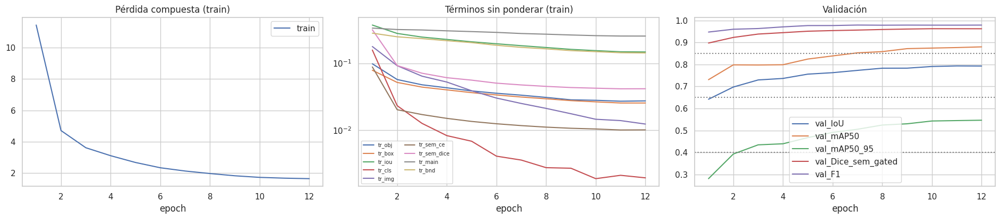

In [ ]:
def run_epoch10(model, loader, lam, opt=None, scaler=None, sched=None):
    train = opt is not None; model.train(train); tot, n = {}, 0
    for batch in loader:
        x, tgt, cm, pres, reg, main, bnd, _ = to_dev(batch)
        with torch.set_grad_enabled(train):
            with amp(): out = model(x)
            parts = loss_parts(out, tgt, cm, pres, reg, main, bnd)
            loss = sum(lam[k] * parts[k] for k in TERMS)
        if train:
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if sched: sched.step()
        for k, v in parts.items(): tot[k] = tot.get(k, 0) + v.item() * len(x)
        tot["total"] = tot.get("total", 0) + loss.item() * len(x); n += len(x)
    return {k: v / n for k, v in tot.items()}

def gate_sem(sem_lbl, boxes, margin=GATE_MARGIN):
    # Etapa 1: la región c solo sobrevive dentro de la caja (tras NMS) de la clase c
    keep = torch.zeros_like(sem_lbl, dtype=torch.bool); H, W = sem_lbl.shape[-2:]
    for x0, y0, x1, y1, s, c in boxes.tolist():
        ys = slice(max(int(y0) - margin, 0), min(int(math.ceil(y1)) + margin, H))
        xs = slice(max(int(x0) - margin, 0), min(int(math.ceil(x1)) + margin, W))
        keep[ys, xs] |= sem_lbl[ys, xs] == int(c) + 1
    return torch.where(keep, sem_lbl, torch.zeros_like(sem_lbl))

@torch.no_grad()
def evaluate_slices(model, loader):
    model.eval(); P, G, pr_p, pr_y = [], [], [], []
    cm_raw = torch.zeros(NSEG * NSEG, dtype=torch.long); cm_gate = cm_raw.clone()
    for batch in loader:
        x, tgt, cmap, pres, reg, main, bnd, gts = to_dev(batch)
        with amp(): out = model(x)
        P_b = [q.cpu() for q in postprocess(out["det"], 0.05, max_per_class=1)]; P += P_b; G += gts
        pr_p.append(out["cls"].float().sigmoid().cpu()); pr_y.append(pres.cpu())
        sem = out["sem"].float().argmax(1).cpu(); g = reg.cpu()
        cm_raw += torch.bincount((g * NSEG + sem).flatten(), minlength=NSEG * NSEG)
        gated = torch.stack([gate_sem(sem[i], P_b[i][P_b[i][:, 4] >= CONF_OP]) for i in range(len(sem))])
        cm_gate += torch.bincount((g * NSEG + gated).flatten(), minlength=NSEG * NSEG)
    det, per_cls = evaluate(P, G)
    pp, py = torch.cat(pr_p).numpy(), torch.cat(pr_y).numpy()
    f1 = f1_score(py, pp >= 0.5, average="macro", zero_division=0)
    aucs = [roc_auc_score(py[:, c], pp[:, c]) for c in range(NC) if 0 < py[:, c].mean() < 1]
    dice = lambda cm: [2 * cm[c, c] / max(cm[c].sum() + cm[:, c].sum(), 1) for c in range(1, NSEG)]
    cmr, cmg = cm_raw.view(NSEG, NSEG).numpy(), cm_gate.view(NSEG, NSEG).numpy()
    res = dict(F1=f1, AUC=float(np.mean(aucs)) if aucs else float("nan"), **det,
               Dice_sem=float(np.mean(dice(cmr))), Dice_sem_gated=float(np.mean(dice(cmg))))
    extra = dict(per_cls=per_cls, dice_r=dice(cmg), cm=cmg, pres=(py, pp), P=P, G=G)
    return res, extra

def train_model(use_cbam=True, ckpt=BACKBONE_CKPT, epochs=EPOCHS10, n_ctx=N_CTX, lam=None, tag="s10", loaders=None, verbose=True):
    torch.manual_seed(SEED); np.random.seed(SEED)
    loaders = loaders or loaders10
    m = PengwinNet10(use_cbam, ckpt, PRIOR10, BND_FRAC, n_ctx).to(DEVICE)
    lam = lam or calibrate_lambdas10(m, loaders["train"])[0]
    opt = torch.optim.AdamW(m.parameters(), lr=LR10, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs * len(loaders["train"]))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    ck = OUT_DIR.parent / f"{tag}_best.pth"; best, log = -1, []
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr = run_epoch10(m, loaders["train"], lam, opt, scaler, sched)
        va, _ = evaluate_slices(m, loaders["val"])
        score = (va["IoU"] + va["Dice_sem_gated"]) / 2
        log.append(dict(epoch=ep, train=tr["total"], **{f"tr_{k}": tr[k] for k in TERMS}, **{f"val_{k}": v for k, v in va.items()}))
        if score > best:
            best = score
            torch.save(dict(model=m.state_dict(), lam=lam, S=S, nout=NOUT, n_ctx=n_ctx, ctx_mm=CTX_MM,
                            use_cbam=use_cbam, ckpt=str(ckpt), epoch=ep, val=va), ck)
        if verbose:
            print(f"ep {ep:02d} | train {tr['total']:.4f} | det IoU {va['IoU']:.3f} mAP50 {va['mAP50']:.3f} "
                  f"mAP50-95 {va['mAP50_95']:.3f} | Dice sem {va['Dice_sem_gated']:.3f} | F1 {va['F1']:.3f} | {time.time()-t0:.0f}s")
    m.load_state_dict(torch.load(ck, map_location=DEVICE, weights_only=False)["model"])
    return m, pd.DataFrame(log).set_index("epoch"), lam

CKPT10 = OUT_ROOT / "s10_best.pth"
if CKPT10.exists() and not RETRAIN10:                       # reanudar: no se pierde el entrenamiento si Colab se reinicia
    ck10 = torch.load(CKPT10, map_location=DEVICE, weights_only=False)
    model10 = PengwinNet10(ck10["use_cbam"], None, PRIOR10, BND_FRAC, ck10["n_ctx"]).to(DEVICE)
    model10.load_state_dict(ck10["model"]); LAMBDA10 = ck10["lam"]
    log10 = pd.read_csv(OUT_DIR / "s10_train_log.csv", index_col="epoch")
    print(f"checkpoint cargado de {CKPT10} (época {ck10['epoch']})")
else:
    model10, log10, LAMBDA10 = train_model(lam=LAMBDA10)
    log10.to_csv(OUT_DIR / "s10_train_log.csv")

fig, ax = plt.subplots(1, 3, figsize=(19, 4.3))
log10[["train"]].plot(ax=ax[0], title="Pérdida compuesta (train)")
log10[[f"tr_{k}" for k in TERMS]].plot(ax=ax[1], logy=True, title="Términos sin ponderar (train)").legend(fontsize=7, ncol=2)
log10[["val_IoU", "val_mAP50", "val_mAP50_95", "val_Dice_sem_gated", "val_F1"]].plot(ax=ax[2], title="Validación")
for y in (0.65, 0.40, 0.85): ax[2].axhline(y, ls=":", c="gray")
plt.tight_layout(); plt.show()

## 25. Métricas por corte en **prueba** (todos los cortes del volumen)
- **Clasificación:** F1 macro y AUC de la cabeza de presencia.
- **Detección:** IoU, mAP@0.5 y mAP@[0.5:0.95].
- **Segmentación semántica:** Dice por región, con y sin el recorte por la caja.
- **Matriz de confusión** a nivel de píxel (fondo / 3 regiones), donde se ve si el modelo confunde izquierda con derecha.

{'F1': 0.981, 'AUC': 0.997, 'IoU': 0.806, 'mAP50': 0.896, 'mAP50_95': 0.581, 'Dice_sem': 0.967, 'Dice_sem_gated': 0.967}


,IoU,AP50,AP50_95,Dice_sem
Sacro,0.663,0.726,0.336,0.954
Coxal izq.,0.853,0.981,0.701,0.971
Coxal der.,0.855,0.981,0.707,0.974


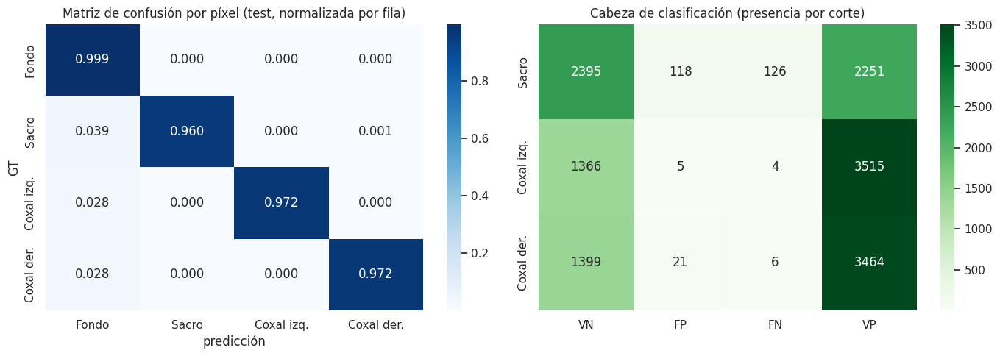

In [ ]:
res_te, ex_te = evaluate_slices(model10, loaders10["test"])
print({k: round(v, 3) for k, v in res_te.items()})
display(ex_te["per_cls"].assign(Dice_sem=ex_te["dice_r"]).round(3))

names = ["Fondo"] + list(REGIONS.values())
cmn = ex_te["cm"] / ex_te["cm"].sum(1, keepdims=True).clip(min=1)
py, pp = ex_te["pres"]
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cmn, annot=True, fmt=".3f", cmap="Blues", xticklabels=names, yticklabels=names, ax=ax[0])
ax[0].set_xlabel("predicción"); ax[0].set_ylabel("GT"); ax[0].set_title("Matriz de confusión por píxel (test, normalizada por fila)")
cm_pres = np.stack([confusion_matrix(py[:, c], pp[:, c] >= 0.5, labels=[0, 1]).ravel() for c in range(NC)])
sns.heatmap(pd.DataFrame(cm_pres, index=list(REGIONS.values()), columns=["VN", "FP", "FN", "VP"]),
            annot=True, fmt="d", cmap="Greens", ax=ax[1]); ax[1].set_title("Cabeza de clasificación (presencia por corte)")
plt.tight_layout(); plt.show()

## 26. Inferencia volumétrica y segmentación de instancia 3D (etapa 2)
El modelo recorre **todos** los cortes del volumen. Las probabilidades semánticas, de **principal** y de **frontera** se suavizan en z con [1, 2, 1]/4 para dar consistencia 3D (antes solo se suavizaba la semántica, y cada corte decidía por su cuenta qué era el principal, lo que generaba componentes espurias). La máscara se recorta por las cajas (etapa 1). Después, para cada región:
1. **Principal** = mayor componente conexa 3D de *región ∧ p(principal) ≥ τ_main*.
2. **Conminutos** = componentes conexas 3D de *región ∧ ¬principal ∧ p(frontera) < τ_bnd* con volumen ≥ `min_mm3`.
3. Los vóxeles de la región que quedan sin asignar (fronteras, componentes pequeñas) van a la instancia más cercana mediante los índices de la EDT.

Cada instancia conserva la región de la que salió, y eso define su color. La evaluación es **fragmentwise**, como en el challenge: emparejamiento húngaro por IoU 3D dentro de cada región. Un fragmento GT sin pareja cuenta con IoU = Dice = 0.

### 26.1 Calibración del post-proceso en **validación**
`min_mm3`, τ_main y τ_bnd se eligen en validación (nunca en test). `min_mm3` se expresa como fracción del **conminuto GT más pequeño de train** (EDA). Criterio: Dice medio sobre GT ∪ falsos positivos (un FP cuenta como Dice 0), así el criterio castiga tanto perder fragmentos como inventarlos.

In [ ]:
del loaders10; gc.collect()

15815

In [ ]:
for k in ("X", "B", "M", "train_boxes", "Btr", "Bva", "img", "lab", "reg", "ins", "img0", "lab0",
          "x0_", "reg0", "b", "o", "hist", "P_val", "G_val", "P_show"):
    globals().pop(k, None)
gc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()

In [ ]:
import sys
def _size(v):
    if isinstance(v, np.ndarray): return v.nbytes
    if torch.is_tensor(v): return v.element_size() * v.nelement()
    if isinstance(v, pd.DataFrame): return int(v.memory_usage(deep=True).sum())
    if isinstance(v, dict): return sum(_size(x) for x in v.values() if not isinstance(x, dict)) + sum(_size(x) for x in v.values() if isinstance(x, dict))
    return 0
top = sorted(((k, _size(v) / 1e9) for k, v in list(globals().items()) if not k.startswith("_")), key=lambda t: -t[1])[:10]
for k, gb in top: print(f"{k:20s} {gb:6.2f} GB")

VOL                    4.21 GB
inst                   0.18 GB
region                 0.09 GB
fr                     0.09 GB
pr                     0.06 GB
v                      0.04 GB
prof_state             0.01 GB
ck10                   0.01 GB
slices                 0.01 GB
lab_sl                 0.01 GB


In [ ]:
for k in ("inst", "region", "fr", "pr", "v"):
    globals().pop(k, None)
gc.collect()

30

In [ ]:
@torch.no_grad()
def infer_volume(model, cid, bs=32, n_ctx=N_CTX):
    v = VOL[cid]; nz = len(v["x"]); model.eval(); H = W = TARGET_SIZE
    probs = torch.zeros(nz, NSEG, H, W, dtype=torch.float16)
    pm = torch.zeros(nz, H, W, dtype=torch.float16); pb = pm.clone(); boxes, pres = [], []
    for i in range(0, nz, bs):
        zs = range(i, min(i + bs, nz))
        x = torch.from_numpy(np.stack([v["x"][ctx_index(nz, z, v["sp"][0], n_ctx)] for z in zs])).float().div(255).to(DEVICE)
        with amp(): o = model(x)
        probs[i:i + len(zs)] = o["sem"].float().softmax(1).half().cpu()
        pm[i:i + len(zs)] = o["main"].float().sigmoid().half().cpu()
        pb[i:i + len(zs)] = o["bnd"].float().sigmoid().half().cpu()
        boxes += [q.cpu() for q in postprocess(o["det"], CONF_OP, max_per_class=1)]
        pres.append(o["cls"].float().sigmoid().cpu())
    def zsmooth(t):                                                     # [1, 2, 1]/4 en z, corte a corte (sin copias float32 del volumen)
        s = t.clone()
        for z in range(1, nz - 1):
            s[z] = ((t[z - 1].float() + 2 * t[z].float() + t[z + 1].float()) / 4).half()
        return s
    sm, pm, pb = zsmooth(probs), zsmooth(pm), zsmooth(pb)
    sem = torch.stack([gate_sem(sm[z].float().argmax(0), boxes[z]) for z in range(nz)]).numpy().astype(np.uint8)
    u8 = lambda t: (t.float() * 255).round().to(torch.uint8).numpy()
    return dict(sem=sem, pmain=u8(pm), pbnd=u8(pb), boxes=boxes, pres=torch.cat(pres).numpy())

def instances_3d(sem, pmain, pbnd, sp, min_mm3=MIN_FRAG_MM3, thr_main=128, thr_bnd=128):
    min_vox = max(1, int(min_mm3 / np.prod(sp)))
    inst = np.zeros(sem.shape, np.int32); info = []; nid = 0
    for r in REGIONS:
        R = sem == r
        if R.sum() < min_vox: continue
        sl = ndi.find_objects(R.astype(np.uint8))[0]; Rs = R[sl]; sub = np.zeros(Rs.shape, np.int32)
        is_main = pmain[sl] >= thr_main
        lm, n = ndi.label(Rs & is_main)
        if n:
            nid += 1; sub[lm == np.bincount(lm.ravel())[1:].argmax() + 1] = nid
            info.append(dict(id=nid, region=r, is_main=True))
        lr_, n = ndi.label(Rs & ~is_main & (pbnd[sl] < thr_bnd))
        if n:
            sizes = np.bincount(lr_.ravel())[1:]
            for j in np.argsort(-sizes):
                if sizes[j] < min_vox: break
                nid += 1; sub[lr_ == j + 1] = nid; info.append(dict(id=nid, region=r, is_main=False))
        if not (sub > 0).any(): continue
        if not any(d["is_main"] and d["region"] == r for d in info):          # sin principal: el más grande lo es
            ids = [d["id"] for d in info if d["region"] == r]
            big = ids[int(np.argmax([(sub == i).sum() for i in ids]))]
            next(d for d in info if d["id"] == big)["is_main"] = True
        un = Rs & (sub == 0)
        if un.any():
            idx = ndi.distance_transform_edt(sub == 0, sampling=sp, return_distances=False, return_indices=True)
            sub[un] = sub[tuple(a[un] for a in idx)]
        inst[sl] = np.where(Rs, sub, inst[sl])
    return inst, pd.DataFrame(info, columns=["id", "region", "is_main"])

def gt_info(cid):
    v = VOL[cid]; ids = np.unique(v["ins"]); ids = ids[ids > 0]
    return pd.DataFrame(dict(id=ids.astype(int), region=v["rlut"][ids].astype(int), is_main=v["mlut"][ids]))

def match_fragments(gins, ginfo, pinst, pinfo, sp):
    vox = float(np.prod(sp)); rows = []
    for r in REGIONS:
        g_ids = ginfo[ginfo.region == r].id.values; p_ids = pinfo[pinfo.region == r].id.values
        if not len(g_ids): continue
        gm, pm_ = np.isin(gins, g_ids), np.isin(pinst, p_ids); m = gm | pm_
        a = np.where(gm[m], gins[m], 0).astype(np.int64); b = np.where(pm_[m], pinst[m], 0).astype(np.int64)
        nb = int(pinst.max()) + 1
        inter = np.bincount(a * nb + b, minlength=256 * nb).reshape(256, nb)
        sa, sb = np.bincount(a, minlength=256), np.bincount(b, minlength=nb)
        I = inter[np.ix_(g_ids, p_ids)] if len(p_ids) else np.zeros((len(g_ids), 0))
        U = sa[g_ids][:, None] + (sb[p_ids][None] if len(p_ids) else 0) - I
        IoU = I / np.maximum(U, 1)
        gi, pj = linear_sum_assignment(-IoU) if len(p_ids) else ([], [])
        pair = {g: (p, IoU[g, p], I[g, p]) for g, p in zip(gi, pj) if IoU[g, p] > 0}
        for gk, gid in enumerate(g_ids):
            p, iou, it = pair.get(gk, (None, 0., 0))
            pid = int(p_ids[p]) if p is not None else None
            rows.append(dict(region=r, gt_id=int(gid), gt_main=bool(ginfo.set_index("id").is_main[gid]),
                             pred_id=pid, pred_main=bool(pinfo.set_index("id").is_main[pid]) if pid else None,
                             iou=float(iou), dice=float(2 * it / max(sa[gid] + (sb[pid] if pid else 0), 1)),
                             vol_gt_mm3=sa[gid] * vox, fp=False))
        fp = set(p_ids) - {int(p_ids[p]) for p, *_ in pair.values()}
        rows += [dict(region=r, gt_id=None, pred_id=int(p), iou=0., dice=0., fp=True) for p in fp]
    return pd.DataFrame(rows)

def separation(inst, info, sp, margin=5):
    # distancia mínima borde a borde (mm) de cada fragmento no principal al principal de su región (misma convención que S8)
    out = {}
    for r in REGIONS:
        ir = info[info.region == r]
        if len(ir) < 2 or not ir.is_main.any(): continue
        main = int(ir[ir.is_main].id.iloc[0]); rm = np.isin(inst, ir.id.values)
        sl = tuple(slice(max(s.start - margin, 0), s.stop + margin) for s in ndi.find_objects(rm.astype(np.uint8))[0])
        sub = inst[sl]; dt = ndi.distance_transform_edt(sub != main, sampling=sp)
        for i in ir[~ir.is_main].id.values:
            m = sub == i
            if m.any(): out[int(i)] = float(dt[m].min())
    return out

def conminuto_rows(cid, mt, gins, ginfo, pinst, pinfo, sp):
    # Estado de cada conminuto GT. El húngaro empareja primero principal↔principal, así que un conminuto fusionado
    # NO tiene pareja propia: se detecta midiendo qué fracción de sus vóxeles cae dentro del principal predicho.
    d_pred, d_gt = separation(pinst, pinfo, sp), separation(gins.astype(np.int32), ginfo, sp)
    main_of = pinfo[pinfo.is_main].set_index("region").id.to_dict(); rows = []
    for _, row in mt[(mt.fp == False) & (mt.gt_main == False)].iterrows():
        gid, r = int(row.gt_id), int(row.region)
        frac_main = float((pinst[gins == gid] == main_of.get(r, -1)).mean())
        has = row.pred_id is not None and not pd.isna(row.pred_id)
        p_is_main = has and bool(row.pred_main)
        if has and not p_is_main and row.iou >= DIST_MIN_IOU: estado = "medido"
        elif p_is_main or frac_main >= FUSION_FRAC:            estado = "fusionado con el principal"
        elif has:                                              estado = "segmentación parcial"
        else:                                                  estado = "no detectado"
        rows.append(dict(case_id=cid, region=REGIONS[r], gt_label=gid, iou=row.iou, frac_en_principal=frac_main,
                         d_gt_256=d_gt.get(gid), d_pred=d_pred.get(int(row.pred_id)) if estado == "medido" else None,
                         estado=estado))
    return rows

def run_instances(cids, raw, min_mm3, thr_main, thr_bnd, with_dist=False):
    FR, DI, OUT = [], [], {}
    for cid in cids:
        v = VOL[cid]; sp = v["sp_rs"]; pr = raw[cid]
        pinst, pinfo = instances_3d(pr["sem"], pr["pmain"], pr["pbnd"], sp, min_mm3, thr_main, thr_bnd)
        ginfo = gt_info(cid); gins = v["ins"]
        mt = match_fragments(gins, ginfo, pinst, pinfo, sp).assign(case_id=cid); FR.append(mt); OUT[cid] = (pinst, pinfo)
        if with_dist: DI += conminuto_rows(cid, mt, gins, ginfo, pinst, pinfo, sp)
    return pd.concat(FR, ignore_index=True), DI, OUT

def frag_scores(fr):
    g = fr[fr.fp == False]
    return dict(dice=g.dice.mean(), iou=g.iou.mean(), dice_main=g[g.gt_main == True].dice.mean(),
                dice_conm=g[g.gt_main == False].dice.mean(), n_fp=int(fr.fp.sum()),
                dice_con_fp=fr.dice.mean())                    # criterio de selección: FP cuentan como 0

# ---- 26.1 calibración en validación · un caso a la vez (no se guardan las predicciones de todos los casos) ----
conm_tr = frags[frags.case_id.isin(splits["train"]) & ~frags.is_main].vol_mm3
MIN_CONM_MM3 = float(conm_tr.quantile(0.05))      # percentil 5: robusto a astillas aisladas
print(f"conminutos de train: mínimo {conm_tr.min():.0f} mm³ · percentil 5 {MIN_CONM_MM3:.0f} mm³ · mediana {conm_tr.median():.0f} mm³")
grid = [(f, tm, tb) for f in (0.10, 0.25, 0.50, 1.00) for tm in (102, 128, 153) for tb in (128, 179)]   # τ en escala 0–255
FR_GRID = {g: [] for g in grid}
for cid in tqdm(splits["val"], desc="calibración post-proceso (val)"):
    v = VOL[cid]; pr = infer_volume(model10, cid); ginfo = gt_info(cid)
    for f, tm, tb in grid:
        pinst, pinfo = instances_3d(pr["sem"], pr["pmain"], pr["pbnd"], v["sp_rs"], f * MIN_CONM_MM3, tm, tb)
        FR_GRID[(f, tm, tb)].append(match_fragments(v["ins"], ginfo, pinst, pinfo, v["sp_rs"]))
        del pinst
    del pr; gc.collect()
cal = pd.DataFrame([dict(frac_min=f, min_mm3=f * MIN_CONM_MM3, thr_main=tm / 255, thr_bnd=tb / 255,
                         **frag_scores(pd.concat(FR_GRID[(f, tm, tb)], ignore_index=True))) for f, tm, tb in grid])
cal = cal.sort_values("dice_con_fp", ascending=False); cal.to_csv(OUT_DIR / "s10_postproc_val.csv", index=False)
display(cal.head(8).round(3))
best = cal.iloc[0]
BEST_PP = dict(min_mm3=float(best.min_mm3), thr_main=int(round(best.thr_main * 255)), thr_bnd=int(round(best.thr_bnd * 255)))
base = cal[(cal.frac_min == 0.10) & (cal.thr_main.round(2) == 0.50) & (cal.thr_bnd.round(2) == 0.50)]
print("post-proceso elegido en validación:", {k: round(v, 3) for k, v in BEST_PP.items()},
      "| referencia (min 10 % del p5, τ = 0.5/0.5):", base[["dice", "n_fp"]].round(3).to_dict("records"))
del FR_GRID; gc.collect()

# ---- test, con el post-proceso fijado en validación · un caso a la vez ----
FR, DI, PRED, SEM3D = [], [], {}, []
for cid in tqdm(splits["test"], desc="inferencia + instancias (test)"):
    v = VOL[cid]; sp = v["sp_rs"]; pr = infer_volume(model10, cid)
    pinst, pinfo = instances_3d(pr["sem"], pr["pmain"], pr["pbnd"], sp, **BEST_PP)
    ginfo = gt_info(cid); gins = v["ins"]
    mt = match_fragments(gins, ginfo, pinst, pinfo, sp).assign(case_id=cid); FR.append(mt)
    DI += conminuto_rows(cid, mt, gins, ginfo, pinst, pinfo, sp)
    greg = v["rlut"][gins]
    for r in REGIONS:
        a, b = greg == r, pr["sem"] == r
        SEM3D.append(dict(case_id=cid, region=REGIONS[r], dice=2 * (a & b).sum() / max(a.sum() + b.sum(), 1)))
    PRED[cid] = dict(inst=pinst.astype(np.uint16), info=pinfo, boxes=pr["boxes"], pres=pr["pres"])   # uint16: ¼ de RAM
    del pr, pinst, greg; gc.collect()
frag_te = pd.concat(FR, ignore_index=True); sem3d = pd.DataFrame(SEM3D)

gt_rows = frag_te[frag_te.fp == False]
frag_summary = pd.DataFrame({
    "todos": gt_rows[["dice", "iou"]].mean(),
    "principal": gt_rows[gt_rows.gt_main == True][["dice", "iou"]].mean(),
    "conminutos": gt_rows[gt_rows.gt_main == False][["dice", "iou"]].mean()}).T
frag_summary["n_GT"] = [len(gt_rows), (gt_rows.gt_main == True).sum(), (gt_rows.gt_main == False).sum()]
frag_summary["falsos_positivos"] = [int(frag_te.fp.sum()), "", ""]
display(frag_summary.round(3))
display(sem3d.groupby("region").dice.describe()[["mean", "min", "max"]].round(3).rename(columns={"mean": "Dice 3D región"}))
frag_te.to_csv(OUT_DIR / "s10_fragments_test.csv", index=False)

conminutos de train: mínimo 282 mm³ · percentil 5 1568 mm³ · mediana 22826 mm³


calibración post-proceso (val):   0%|          | 0/15 [00:00<?, ?it/s]

,frac_min,min_mm3,thr_main,thr_bnd,dice,iou,dice_main,dice_conm,n_fp,dice_con_fp
22,1.00,1567.579,0.600,0.502,0.664,0.591,0.909,0.381,29,0.494
18,1.00,1567.579,0.400,0.502,0.493,0.453,0.907,0.015,1,0.487
23,1.00,1567.579,0.600,0.702,0.664,0.589,0.909,0.381,31,0.485
21,1.00,1567.579,0.502,0.702,0.558,0.503,0.908,0.154,13,0.483
19,1.00,1567.579,0.400,0.702,0.499,0.457,0.907,0.029,3,0.482
12,0.50,783.790,0.400,0.502,0.499,0.457,0.907,0.028,3,0.482
6,0.25,391.895,0.400,0.502,0.508,0.464,0.908,0.046,6,0.474
20,1.00,1567.579,0.502,0.502,0.535,0.482,0.907,0.105,11,0.473


post-proceso elegido en validación: {'min_mm3': 1567.579, 'thr_main': 153, 'thr_bnd': 128} | referencia (min 10 % del p5, τ = 0.5/0.5): [{'dice': 0.572, 'n_fp': 76}]


inferencia + instancias (test):   0%|          | 0/15 [00:00<?, ?it/s]

,dice,iou,n_GT,falsos_positivos
todos,0.627,0.564,84,23
principal,0.921,0.860,45,
conminutos,0.288,0.222,39,


,Dice 3D región,min,max
region,,,
Coxal der.,0.973,0.959,0.980
Coxal izq.,0.970,0.958,0.980
Sacro,0.953,0.875,0.976


## 27. Distancia de separación: predicción vs *ground truth*
Se calcula con `distance_transform_edt(~principal, sampling=espaciado)`, usando el espaciado del header ajustado al remuestreo (`sp_rs`). Se comparan tres valores:
- **GT original** (sección 7, resolución nativa).
- **GT a 256 px:** aísla el error que introduce el remuestreo.
- **Predicción a 256 px:** la diferencia con el GT a 256 px es el error que **transfiere la segmentación**.

**Cómo leer el resultado.**
- **Cobertura.** El error solo existe para los conminutos *medidos* (pareja predicha propia con IoU 3D ≥ `DIST_MIN_IOU`). Los *fusionados con el principal*, los de *segmentación parcial* y los *no detectados* no tienen distancia predicha. Por eso se reporta qué fracción se pudo medir.
- **Contacto vs separados.** Cerca del 90 % de los conminutos GT toca al principal (EDA). En ellos ambas distancias valen ≈ 1 vóxel, así que un error ≈ 0 **no prueba nada**. El error informativo es el de los conminutos **separados** (d_GT > 1.5 × el espaciado máximo del caso), que se reporta aparte.

en_contacto,en contacto,separado,total
estado,,,
fusionado con el principal,20,0,20
medido,11,4,15
no detectado,2,2,4
total,33,6,39


Cobertura de la medición: 38.5 % de los conminutos GT de test (15/39)


d_gt_256                    d_pred                    err_seg  \
               count  mean median   max  count  mean median   max   count   
en_contacto                                                                 
en contacto       11  0.89   0.80  1.00     11  0.94    0.8  1.55      11   
separado           4  2.61   2.61  3.28      4  1.58    1.0  3.34       4   

                                
             mean median   max  
en_contacto                     
en contacto  0.05   0.00  0.55  
separado     1.72   1.61  2.28

,count,mean,std,min,25%,50%,75%,max
err_resample,39.0,0.15,0.15,0.0,0.02,0.12,0.22,0.62


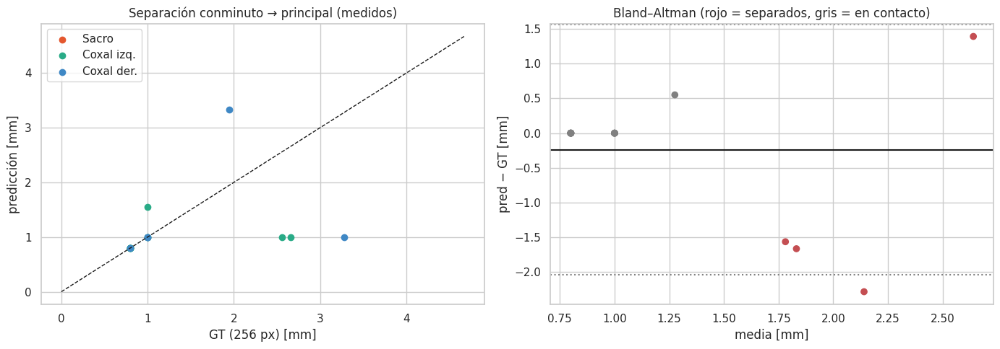

In [ ]:
dist_te = pd.DataFrame(DI)
gt_orig = dist.set_index(["case_id", "label"]).dist_mm
dist_te["d_gt_orig"] = [gt_orig.get((c, l)) for c, l in zip(dist_te.case_id, dist_te.gt_label)]
sp_max = vols.set_index("case_id")[["sp_x", "sp_z"]].max(1)
dist_te["en_contacto"] = dist_te.d_gt_orig <= 1.5 * dist_te.case_id.map(sp_max)
dist_te["err_resample"] = (dist_te.d_gt_256 - dist_te.d_gt_orig).abs()
dist_te["err_seg"] = (dist_te.d_pred - dist_te.d_gt_256).abs()
dist_te.to_csv(OUT_DIR / "s10_separation_test.csv", index=False)

cob = pd.crosstab(dist_te.estado, dist_te.en_contacto.map({True: "en contacto", False: "separado"}), margins=True, margins_name="total")
display(cob)
print(f"Cobertura de la medición: {(dist_te.estado == 'medido').mean()*100:.1f} % de los conminutos GT de test "
      f"({(dist_te.estado == 'medido').sum()}/{len(dist_te)})")
med = dist_te[dist_te.estado == "medido"]
err = med.groupby(med.en_contacto.map({True: "en contacto", False: "separado"}))[["d_gt_256", "d_pred", "err_seg"]].agg(["count", "mean", "median", "max"])
display(err.round(2))
display(dist_te[["err_resample"]].describe().T.round(2))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
if len(med):
    for r in REGIONS:
        s = med[med.region == REGIONS[r]]
        ax[0].scatter(s.d_gt_256, s.d_pred, c=REGION_COLORS[r], label=REGIONS[r], marker="o")
    lim = max(med.d_gt_256.max(), med.d_pred.max()) * 1.1 + 1; ax[0].plot([0, lim], [0, lim], "k--", lw=1)
    mean_, diff_ = (med.d_pred + med.d_gt_256) / 2, med.d_pred - med.d_gt_256
    ax[1].scatter(mean_, diff_, c=np.where(med.en_contacto, "gray", "C3"))
    ax[1].axhline(diff_.mean(), c="k")
    for s_ in (-1.96, 1.96): ax[1].axhline(diff_.mean() + s_ * diff_.std(), c="gray", ls=":")
ax[0].set_xlabel("GT (256 px) [mm]"); ax[0].set_ylabel("predicción [mm]"); ax[0].legend(); ax[0].set_title("Separación conminuto → principal (medidos)")
ax[1].set_xlabel("media [mm]"); ax[1].set_ylabel("pred − GT [mm]"); ax[1].set_title("Bland–Altman (rojo = separados, gris = en contacto)")
plt.tight_layout(); plt.show()

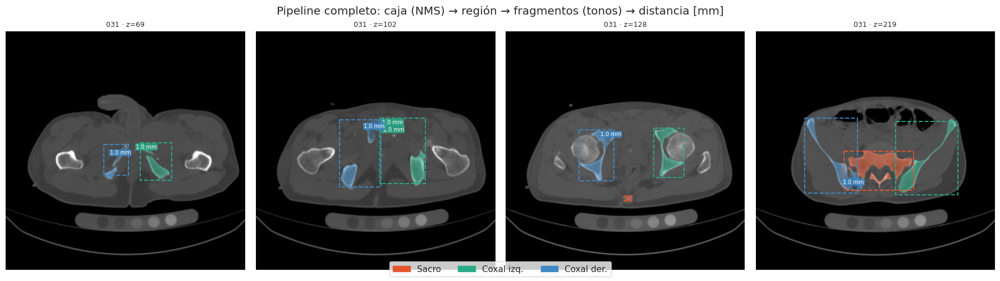

In [ ]:
# Vista previa del Visualizador 2 (S11): instancias coloreadas por región + distancia junto a cada fragmento
def shade(col, k):
    rgb = np.array([int(col[i:i + 2], 16) / 255 for i in (1, 3, 5)]); return (rgb * (1 - 0.3 * k)).clip(0, 1)

def overlay_instances(ax, cid, z, title=""):
    v, p = VOL[cid], PRED[cid]; inst, info = p["inst"], p["info"]
    d = separation(inst, info, v["sp_rs"]); ax.imshow(v["x"][z], cmap="gray")
    rgba = np.zeros((*inst.shape[1:], 4))
    for k, row in info.iterrows():
        m = inst[z] == row.id
        if not m.any(): continue
        rank = (info[(info.region == row.region)].id < row.id).sum()
        rgba[m] = [*shade(REGION_COLORS[row.region], rank), .55]
        if not row.is_main and row.id in d:
            ys, xs = np.nonzero(m); ax.text(xs.mean(), ys.mean(), f"{d[row.id]:.1f} mm", color="w", fontsize=7,
                                            ha="center", bbox=dict(fc=REGION_COLORS[row.region], alpha=.8, lw=0, pad=1))
    ax.imshow(rgba)
    for x0, y0, x1, y1, s, c in p["boxes"][z].tolist():
        ax.add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=REGION_COLORS[int(c) + 1], lw=1.4, ls="--"))
    ax.set_title(title, fontsize=9); ax.axis("off")

cid = frag_te.groupby("case_id").gt_id.count().idxmax()
zs = np.nonzero(np.isin(PRED[cid]["inst"], PRED[cid]["info"][~PRED[cid]["info"].is_main].id.values).any((1, 2)))[0]
zs = zs if len(zs) else np.nonzero(PRED[cid]["inst"].any((1, 2)))[0]
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for a, z in zip(axes, np.quantile(zs, [.15, .4, .6, .85]).astype(int)):
    overlay_instances(a, cid, z, f"{cid} · z={z}")
fig.legend(handles=[mpatches.Patch(color=REGION_COLORS[r], label=REGIONS[r]) for r in REGIONS], loc="lower center", ncol=3)
plt.suptitle("Pipeline completo: caja (NMS) → región → fragmentos (tonos) → distancia [mm]"); plt.tight_layout(); plt.show()

## 28. SAM como baseline *zero-shot* (sección 4.2)
SAM (ViT-B) recibe como *prompt* la **caja predicha** por nuestro detector sobre cortes de prueba y se compara contra nuestra máscara de región dentro de la misma caja. Ambas se miden frente al GT con Dice e IoU. SAM **no** forma parte del pipeline: solo sirve como evidencia de cómo rinde un modelo generalista fuera de dominio frente a uno entrenado para la tarea.

In [ ]:
RUN_SAM, N_SAM = True, 300
SAM_CKPT = Path("./sam_vit_b_01ec64.pth")
sam_res = None
if RUN_SAM:
    try:
        from segment_anything import sam_model_registry, SamPredictor
    except ImportError:
        !pip -q install segment-anything
        from segment_anything import sam_model_registry, SamPredictor
    if not SAM_CKPT.exists():
        !wget -q -nc https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth
    sam = sam_model_registry["vit_b"](checkpoint=str(SAM_CKPT)).to(DEVICE).eval(); predictor = SamPredictor(sam)
    rng = np.random.default_rng(SEED)
    cand = [(c, z) for c in splits["test"] for z in range(len(VOL[c]["x"])) if len(PRED[c]["boxes"][z])]
    pick = [cand[i] for i in rng.choice(len(cand), min(N_SAM, len(cand)), replace=False)]
    rows, t_sam, t_own = [], 0., 0.
    for cid, z in tqdm(pick, desc="SAM"):
        v = VOL[cid]; img = v["x"][z]; greg = v["rlut"][v["ins"][z]]
        t0 = time.perf_counter(); predictor.set_image(np.repeat(img[..., None], 3, -1)); t_sam += time.perf_counter() - t0
        for x0, y0, x1, y1, s, c in PRED[cid]["boxes"][z].tolist():
            r = int(c) + 1; g = greg == r
            t0 = time.perf_counter()
            m_sam = predictor.predict(box=np.array([x0, y0, x1, y1]), multimask_output=False)[0][0]
            t_sam += time.perf_counter() - t0
            m_own = np.isin(PRED[cid]["inst"][z], PRED[cid]["info"][PRED[cid]["info"].region == r].id.values)
            for name, m in (("SAM (zero-shot)", m_sam), ("Modelo propio", m_own)):
                inter, uni = (m & g).sum(), (m | g).sum()
                rows.append(dict(modelo=name, region=REGIONS[r], dice=2 * inter / max(m.sum() + g.sum(), 1), iou=inter / max(uni, 1)))
    sam_res = pd.DataFrame(rows)
    display(sam_res.groupby(["modelo", "region"])[["dice", "iou"]].mean().unstack(0).round(3))
    display(sam_res.groupby("modelo")[["dice", "iou"]].mean().round(3))
    print(f"SAM: {t_sam / len(pick) * 1000:.0f} ms por corte (embedding + prompts) sobre {len(pick)} cortes")
    sam_res.to_csv(OUT_DIR / "s10_sam_vs_propio.csv", index=False)
    del sam, predictor; gc.collect()

SAM:   0%|          | 0/300 [00:00<?, ?it/s]

dice                           iou                
modelo     Modelo propio SAM (zero-shot) Modelo propio SAM (zero-shot)
region                                                                
Coxal der.         0.958           0.900         0.929           0.834
Coxal izq.         0.958           0.892         0.928           0.823
Sacro              0.889           0.746         0.841           0.643

,dice,iou
modelo,,
Modelo propio,0.940,0.906
SAM (zero-shot),0.857,0.781


SAM: 495 ms por corte (embedding + prompts) sobre 300 cortes


## 29. Ablación: CBAM, *transfer learning* y contexto 3D
Se entrena con menos épocas (`ABL_EPOCHS = 4`), sobre un subconjunto fijo de `ABL_MAX_TRAIN_CASES = 24` casos de *train*, con la **misma** semilla, splits y λ. Así solo cambia un factor a la vez y la ablación cabe en una sesión de Colab. Se evalúa en validación.
- **Completo:** CBAM y contexto 2.5D con N = 5 cortes (±2 y ±4 mm).
- **Sin CBAM:** el módulo de atención se reemplaza por la identidad.

In [ ]:
RUN_ABLATION, ABL_EPOCHS, ABL_MAX_TRAIN_CASES = True, 4, 24
abl = None
if RUN_ABLATION:
    falta = [n for n in ("N_CTX", "train_model", "evaluate_slices", "make_loaders", "LAMBDA10", "VOL") if n not in globals()]
    assert not falta, f"El entorno se reinició: falta {falta}. Ejecuten de nuevo las secciones 1–24 antes de la ablación."
    abl_ids = sorted(np.random.default_rng(SEED).choice(splits["train"], min(ABL_MAX_TRAIN_CASES, len(splits["train"])), replace=False).tolist())
    configs = [dict(nombre="completo (CBAM, 3D N=5" + (", transfer)" if BACKBONE_CKPT else ")"), use_cbam=True, n_ctx=N_CTX, ckpt=BACKBONE_CKPT),
               dict(nombre="sin CBAM", use_cbam=False, n_ctx=N_CTX, ckpt=BACKBONE_CKPT)]
    if BACKBONE_CKPT is not None:
        configs.append(dict(nombre="sin transfer learning", use_cbam=True, n_ctx=N_CTX, ckpt=None))
    else:
        print("⚠ Sin pesos del Taller 3: la comparación con/sin transfer learning no se puede ejecutar; se declara en el informe.")
    ABL_CSV = OUT_DIR / "s10_ablation_val.csv"
    done = pd.read_csv(ABL_CSV) if ABL_CSV.exists() else pd.DataFrame(columns=["config"])
    loaders_abl = {}
    for cfg in configs:
        if cfg["nombre"] in set(done.config):
            print("ya calculada:", cfg["nombre"]); continue
        if cfg["n_ctx"] not in loaders_abl: loaders_abl[cfg["n_ctx"]] = make_loaders(cfg["n_ctx"], train_ids=abl_ids)
        ld = loaders_abl[cfg["n_ctx"]]; t0 = time.time()
        m, lg, _ = train_model(cfg["use_cbam"], cfg["ckpt"], ABL_EPOCHS, cfg["n_ctx"], lam=LAMBDA10,
                               tag="abl_" + re.sub(r"\W+", "_", cfg["nombre"]), loaders=ld, verbose=False)
        va, _ = evaluate_slices(m, ld["val"])
        row = dict(config=cfg["nombre"], **{k: va[k] for k in ("F1", "AUC", "IoU", "mAP50", "mAP50_95", "Dice_sem_gated")},
                   params_M=n_par(m), min=(time.time() - t0) / 60)
        done = pd.concat([done, pd.DataFrame([row])], ignore_index=True); done.to_csv(ABL_CSV, index=False)
        print(f"{cfg['nombre']}: listo en {row['min']:.0f} min")
        del m; gc.collect(); torch.cuda.empty_cache() if torch.cuda.is_available() else None
    abl = done.set_index("config")
    display(abl.round(3))

⚠ Sin pesos del Taller 3: la comparación con/sin transfer learning no se puede ejecutar; se declara en el informe.
completo (CBAM, 3D N=5): listo en 16 min
sin CBAM: listo en 16 min


**Resultados de la ablación** (validación; 4 épocas sobre 24 casos de *train*; leídos de `outputs/s10_ablation_val.csv`)

| Configuración | F1 | AUC | IoU | mAP@0.5 | mAP@[0.5:0.95] | Dice semántico |
|---|---|---|---|---|---|---|
| Completo (CBAM, 2.5D N = 5) | 0.954 | 0.988 | 0.692 | 0.766 | 0.384 | 0.921 |
| Sin CBAM | 0.947 | 0.984 | 0.677 | 0.732 | 0.366 | 0.911 |

Quitar CBAM baja todas las métricas: −0.034 en mAP@0.5, −0.018 en mAP@[0.5:0.95] y −0.010 en Dice semántico. La atención aporta sobre todo a la localización de las cajas.

## 30. Latencia por imagen (CPU y GPU) y exportación para el dashboard

In [ ]:
@torch.no_grad()
def latency10(m, device, n=30, warmup=5):
    m = m.to(device).eval(); x = torch.rand(1, N_CTX, TARGET_SIZE, TARGET_SIZE, device=device)
    def step():
        o = m(x); b = postprocess(o["det"], CONF_OP); gate_sem(o["sem"][0].argmax(0).cpu(), b[0].cpu())
    for _ in range(warmup): step()
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(n): step()
    if device.type == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t0) / n * 1000

lat10 = {"CPU": latency10(model10, torch.device("cpu"))}
if torch.cuda.is_available(): lat10["GPU"] = latency10(model10, torch.device("cuda"))
model10.to(DEVICE)
print({k: f"{v:.1f} ms/corte (3 cabezas + NMS + recorte por caja)" for k, v in lat10.items()})

# Latencia de un volumen completo (inferencia de todos los cortes + instancias 3D) en el dispositivo actual
cid0 = splits["test"][0]
if DEVICE.type == "cuda": torch.cuda.synchronize()
t0 = time.perf_counter(); pr0 = infer_volume(model10, cid0)
if DEVICE.type == "cuda": torch.cuda.synchronize()
t1 = time.perf_counter(); instances_3d(pr0["sem"], pr0["pmain"], pr0["pbnd"], VOL[cid0]["sp_rs"], **BEST_PP); t2 = time.perf_counter()
lat10["volumen_" + DEVICE.type.upper()] = dict(cortes=len(VOL[cid0]["x"]), red_s=round(t1 - t0, 2), instancias_s=round(t2 - t1, 2))
print(f"Volumen {cid0} ({len(VOL[cid0]['x'])} cortes) en {DEVICE.type.upper()}: red {t1-t0:.1f} s + instancias 3D {t2-t1:.1f} s")
del pr0

{'CPU': '175.7 ms/corte (3 cabezas + NMS + recorte por caja)', 'GPU': '10.2 ms/corte (3 cabezas + NMS + recorte por caja)'}
Volumen 001 (401 cortes) en CUDA: red 8.3 s + instancias 3D 1.3 s


In [ ]:
TARGETS = [("Clasificación", "F1", res_te["F1"], 0.85), ("Clasificación", "AUC", res_te["AUC"], 0.85),
           ("Detección", "IoU promedio", res_te["IoU"], 0.65), ("Detección", "mAP@0.50", res_te["mAP50"], 0.65),
           ("Detección", "mAP@[0.50:0.95]", res_te["mAP50_95"], 0.40),
           ("Segmentación de fragmento", "Dice (fragmentwise 3D)", frag_summary.loc["todos", "dice"], 0.85),
           ("Segmentación de fragmento", "IoU (fragmentwise 3D)", frag_summary.loc["todos", "iou"], 0.70),
           ("Segmentación (referencia)", "Dice fragmento principal", frag_summary.loc["principal", "dice"], 0.85),
           ("Segmentación (referencia)", "Dice 3D por región", sem3d.dice.mean(), 0.85)]
obj = pd.DataFrame(TARGETS, columns=["Tarea", "Métrica", "Test", "Objetivo"])
obj["Cumple"] = np.where(obj.Test >= obj.Objetivo, "✓", "✗")
display(obj.round(3))

summary10 = dict(test=res_te, fragmentos=frag_summary.drop(columns="falsos_positivos").to_dict(), latencia_ms=lat10,
                 lambda_=LAMBDA10, pos_weight_obj=POS_W10, pos_weight_bnd=BND_PW, n_ctx=N_CTX, ctx_mm=CTX_MM,
                 aug=AUG, costo_perdida=cost.to_dict(), postproceso=BEST_PP, backbone_ckpt=BACKBONE_CKPT,
                 cobertura_distancia=float((dist_te.estado == "medido").mean()), ablacion=None if abl is None else abl.to_dict(),
                 sam=None if sam_res is None else sam_res.groupby("modelo")[["dice", "iou"]].mean().to_dict())
json.dump(summary10, open(OUT_DIR / "s10_summary.json", "w"), indent=2, default=str)
print("checkpoint:", CKPT10, "| resultados en", OUT_DIR)

,Tarea,Métrica,Test,Objetivo,Cumple
0,Clasificación,F1,0.981,0.85,✓
1,Clasificación,AUC,0.997,0.85,✓
2,Detección,IoU promedio,0.806,0.65,✓
3,Detección,mAP@0.50,0.896,0.65,✓
4,Detección,mAP@[0.50:0.95],0.581,0.40,✓
5,Segmentación de fragmento,Dice (fragmentwise 3D),0.627,0.85,✗
6,Segmentación de fragmento,IoU (fragmentwise 3D),0.564,0.70,✗
7,Segmentación (referencia),Dice fragmento principal,0.921,0.85,✓
8,Segmentación (referencia),Dice 3D por región,0.965,0.85,✓


checkpoint: /content/drive/MyDrive/PENGWIN_outputs/s10_best.pth | resultados en /content/drive/MyDrive/PENGWIN_outputs/eda


## 30.1 Exportación para el dashboard (S11)
Por cada caso de test se guarda en Drive (`outputs/dashboard/`) un `.npz` con el volumen a 256 px, las instancias predichas, el GT, las cajas por corte y el espaciado, más un `.json` con la tabla de fragmentos (región, principal, distancia en mm). El dashboard carga estos archivos al instante y además puede correr la inferencia en vivo con `s10_best.pth`.

In [ ]:
EXPORT_DIR = OUT_ROOT / "dashboard"; EXPORT_DIR.mkdir(parents=True, exist_ok=True)
for cid in tqdm(splits["test"], desc="exportando"):
    v, p = VOL[cid], PRED[cid]; nz = len(v["x"])
    B = np.full((nz, NC, 6), np.nan, np.float32)
    for z, b in enumerate(p["boxes"]):
        for k, row in enumerate(b.numpy()[:NC]): B[z, k] = row
    d = separation(p["inst"], p["info"], v["sp_rs"])
    np.savez_compressed(EXPORT_DIR / f"{cid}.npz", x=v["x"], inst=p["inst"].astype(np.uint16), gt=v["ins"], rlut=v["rlut"],
                        boxes=B, sp_rs=np.array(v["sp_rs"]), sp=np.array(v["sp"]), scale=v["scale"],
                        pad=np.array(v["pad"]), shape=np.array(v["shape"]))
    info = p["info"].assign(dist_mm=p["info"].id.map(d)).to_dict("records")
    json.dump(dict(case_id=cid, image=cases.set_index("case_id").loc[cid, "image"], fragments=info),
              open(EXPORT_DIR / f"{cid}.json", "w"), indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
cfg = dict(regions=REGIONS, colors=REGION_COLORS, window=WINDOW, hu_bone_thr=HU_BONE_THR, target_size=TARGET_SIZE,
           S=S, nout=NOUT, n_ctx=N_CTX, ctx_mm=CTX_MM, conf_op=CONF_OP, gate_margin=GATE_MARGIN, postproceso=BEST_PP,
           splits=splits, latencia_ms=lat10, metas=obj.to_dict("records"))
json.dump(cfg, open(EXPORT_DIR / "config.json", "w"), indent=1, default=str)
print("exportado a", EXPORT_DIR, "|", len(splits["test"]), "casos de test")

exportando:   0%|          | 0/15 [00:00<?, ?it/s]

exportado a /content/drive/MyDrive/PENGWIN_outputs/dashboard | 15 casos de test


## 31. Pendientes para la semana 11 (entrega)
- Visualizador 2 con *slider* (la base es `overlay_instances`) y Visualizador 3: apilar las instancias → `skimage.measure.marching_cubes` → `plotly Mesh3d`, con la distancia en la etiqueta de cada fragmento. Insumos en `outputs/dashboard/`.
- Dashboard + túnel de Cloudflare; latencia CPU/GPU por corte y por volumen ya medida (sección 30).
- Informe: ablación (sección 29), matriz de confusión (sección 25), galería de los 5 peores casos (`frag_te` ordenado por Dice) y comparación de distancias con cobertura (sección 27).
- *Model card*: conminutos «fusionados con el principal» (sección 27), advertencia de uso no clínico.